# Fine-Tuning: gespeicherte Ergebnisse

Dieses Notebook liest ausschließlich vorhandene Exporte. Kein Training, keine neue Optimierung, kein Bootstrap und keine Neuberechnung von Kennzahlen.

**MC: vier von fünf Folds, ausschließlich vorläufig.** Die anderen Tasks haben ihre ursprüngliche vollständige Partition. Fehlgeschlagene Modellstreams sind nicht verfügbar; ihre Kennzahlen dürfen nicht aus erfolgreichen Teilfolds ergänzt werden. Der Lauf ist eine adaptive Nachanalyse derselben Partition, keine unabhängige Validierung.


In [1]:
import os, json, hashlib
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image, FileLink

REPO = Path.cwd().resolve()
if not (REPO / "revision").is_dir() and (REPO.parent / "revision").is_dir():
    REPO = REPO.parent
RESULTS = Path(
    os.environ.get(
        "IIVV_FINETUNING_RESULTS", "results/revision-finetuning-20261102-122955"
    )
)
if not RESULTS.is_absolute():
    RESULTS = REPO / RESULTS
RESULTS = RESULTS.resolve()
manifest = json.loads((RESULTS / "run_manifest.json").read_text())
if manifest["status"] not in {"completed", "completed_partial"}:
    raise ValueError(
        "Der Run hat seine geplanten Berechnungen noch nicht abgeschlossen."
    )
cfg = manifest["config"]
if not cfg.get("fine_tuning"):
    raise ValueError("Kein Fine-Tuning-Run.")
TASKS = cfg["tasks"]
print(RESULTS, "\nStatus:", manifest["status"])


def file_link(path):
    display(FileLink(os.path.relpath(path, Path.cwd())))


def read_table(path):
    if not path.is_file() or not path.stat().st_size:
        return pd.DataFrame()
    try:
        return pd.read_csv(path)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


def show_table(path, limit=80):
    display(Markdown("**" + str(path.relative_to(RESULTS)) + "**"))
    if not path.is_file():
        print("Nicht verfügbar.")
        return
    file_link(path)
    frame = read_table(path)
    display(frame.head(limit))
    if len(frame) > limit:
        print(
            f"{len(frame)} Zeilen; Vorschau mit {limit} Zeilen. Vollständige Datei über den Link."
        )

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955 
Status: completed_partial


## Vollständigkeit und Integrität

Prüfung des eingefrorenen Plans und aller kopierten Checkpoint-Dateien anhand der gespeicherten SHA-256-Werte. Die ursprünglichen Eingabedaten und die wissenschaftliche Korrektheit werden hier nicht erneut geprüft. Ein bestandener Check macht MC nicht vollständig.


In [2]:
def sha256(path):
    with path.open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


plan_path = RESULTS / "fine_tuning_plan.json"
if sha256(plan_path) != manifest["fine_tuning_plan_sha256"]:
    raise ValueError("Fine-Tuning-Plan verändert oder unvollständig kopiert.")
plan = json.loads(plan_path.read_text())
expected = {
    f"{task}/nested_cv_repeat0_fold{fold}"
    for task in TASKS
    for fold in cfg["fine_tuning"]["folds"][task]
}
if set(plan) != expected:
    raise ValueError("Falsches Fold-Inventar.")
for identity in sorted(expected):
    folder = RESULTS / "fold-checkpoints" / identity
    marker = json.loads((folder / "complete.json").read_text())
    task = identity.split("/")[0]
    fold = plan[identity]["split"]["outer_fold"]
    if marker["task"] != task or marker["fold_key"] != [0, fold, "nested_cv"]:
        raise ValueError("Falsche Checkpoint-Identität: " + identity)
    for name, checksum in marker["artifacts"].items():
        artifact = (folder / name).resolve()
        if (
            not artifact.is_relative_to(folder.resolve())
            or sha256(artifact) != checksum
        ):
            raise ValueError("Verändertes Checkpoint-Artefakt: " + str(artifact))
print(f"{len(expected)} vollständige kopierte Checkpoints geprüft.")
display(
    pd.DataFrame(
        [
            dict(
                task=task,
                folds=len(cfg["fine_tuning"]["folds"][task]),
                expected=cfg["outer_folds"],
                scope=(
                    "VORLÄUFIG"
                    if len(cfg["fine_tuning"]["folds"][task]) < cfg["outer_folds"]
                    else "vollständige ursprüngliche Partition"
                ),
            )
            for task in TASKS
        ]
    )
)
if (RESULTS / "REVIEW_RESULTS.md").is_file():
    display(Markdown((RESULTS / "REVIEW_RESULTS.md").read_text()))

19 vollständige kopierte Checkpoints geprüft.


,task,folds,expected,scope
0,healthy_vs_cancer,5,5,vollständige ursprüngliche Partition
1,cancer_vs_lr_hr,5,5,vollständige ursprüngliche Partition
2,MC,4,5,VORLÄUFIG
3,highrisk_vs_lowrisk,5,5,vollständige ursprüngliche Partition


# Reduced fold-specific fine tuning

Original inner-training winners only; original patient partition reused.
This is an additional adaptive analysis, not independent validation.

| Task | Folds | Evidence |
|---|---:|---|
| healthy_vs_cancer | 5/5 | complete partition |
| cancer_vs_lr_hr | 5/5 | complete partition |
| MC | 4/5 | PARTIAL: exclude from final claims |
| highrisk_vs_lowrisk | 5/5 | complete partition |

19 fold jobs. No source classifier results copied as new results.

See classification_outputs.csv for AUC/F1/precision/SN/SP/PPV/NPV and patient-bootstrap CIs;
corrected_resampled_tests_holm.csv for corrected CV tests; review_selected_parameters.csv for settings.
MC statistics/intervals condition on the four available folds; they do not represent the full cohort.
Ablations were not rerun; unavailable_streams.json records their absence.
Failed model fits were skipped, not accepted as converged.
Incomplete streams have no pooled performance claim; see unavailable_results.csv.


## Metriken und Konfidenzintervalle

`all_metrics.csv` enthält die gespeicherten Punktschätzungen; `classification_outputs.csv` die einzelnen Metriken mit patientenweisen Bootstrap-Intervallen. Precision und PPV sind identisch. Die Auswahl `patient_weighted_site` gewichtet Patienten gleich; `site` und `patient` sind getrennte Endpunkte. MC-Zahlen gelten nur für die vorhandenen vier Folds.


In [3]:
UNIT = "patient_weighted_site"  # alternativ: site oder patient
for filename in ["all_metrics.csv", "classification_outputs.csv"]:
    path = RESULTS / filename
    frame = read_table(path)
    if "unit" in frame:
        frame = frame[frame.unit == UNIT]
    for task in TASKS:
        display(Markdown(f"### {task}: {filename}"))
        part = frame[frame.task == task] if "task" in frame else frame
        display(part.head(150))
        if len(part) > 150:
            print(f"Vorschau: 150 von {len(part)} Zeilen; vollständige Datei unten.")
    file_link(path)
for filename in ["BaselineResults.csv", "FinalResults.csv"]:
    show_table(RESULTS / filename)

### healthy_vs_cancer: all_metrics.csv

,task,stream,evaluation,unit,n_sites,n_covered,n_patients,coverage,accuracy,balanced_accuracy,...,ppv,macro_npv,npv,tp,fn,fp,tn,folds_available,folds_expected,evidence_status
1,healthy_vs_cancer,acc_lr,nested_cv,patient_weighted_site,196,195,98,0.989796,0.824055,0.817427,...,0.783623,0.817599,0.851574,61.566667,17.133333,17.000000,98.300000,5,5,complete_partition
4,healthy_vs_cancer,acc_rf,nested_cv,patient_weighted_site,196,195,98,0.989796,0.806529,0.795154,...,0.776286,0.800835,0.825384,57.833333,20.866667,16.666667,98.633333,5,5,complete_partition
7,healthy_vs_cancer,acc_selected,nested_cv,patient_weighted_site,196,195,98,0.989796,0.803780,0.795799,...,0.760581,0.796694,0.832807,59.300000,19.400000,18.666667,96.633333,5,5,complete_partition
10,healthy_vs_cancer,acc_svm,nested_cv,patient_weighted_site,196,195,98,0.989796,0.831271,0.824305,...,0.794784,0.825286,0.855789,61.966667,16.733333,16.000000,99.300000,5,5,complete_partition
13,healthy_vs_cancer,auc_lr,nested_cv,patient_weighted_site,196,195,98,0.989796,0.814433,0.805568,...,0.778357,0.808190,0.838022,59.700000,19.000000,17.000000,98.300000,5,5,complete_partition
16,healthy_vs_cancer,auc_rf,nested_cv,patient_weighted_site,196,195,98,0.989796,0.798969,0.797936,...,0.733438,0.791772,0.850107,62.366667,16.333333,22.666667,92.633333,5,5,complete_partition
19,healthy_vs_cancer,auc_selected,nested_cv,patient_weighted_site,196,195,98,0.989796,0.792955,0.794557,...,0.719272,0.786614,0.853957,63.200000,15.500000,24.666667,90.633333,5,5,complete_partition
22,healthy_vs_cancer,auc_svm,nested_cv,patient_weighted_site,196,195,98,0.989796,0.813574,0.815937,...,0.742033,0.807417,0.872802,65.200000,13.500000,22.666667,92.633333,5,5,complete_partition
25,healthy_vs_cancer,baseline_lr,nested_cv,patient_weighted_site,196,186,98,0.941327,0.780488,0.778767,...,0.731422,0.775812,0.820203,60.366667,18.333333,22.166667,83.633333,5,5,complete_partition
28,healthy_vs_cancer,baseline_rf,nested_cv,patient_weighted_site,196,186,98,0.941327,0.810298,0.803132,...,0.791204,0.807295,0.823386,59.366667,19.333333,15.666667,90.133333,5,5,complete_partition


### cancer_vs_lr_hr: all_metrics.csv

,task,stream,evaluation,unit,n_sites,n_covered,n_patients,coverage,accuracy,balanced_accuracy,...,ppv,macro_npv,npv,tp,fn,fp,tn,folds_available,folds_expected,evidence_status
67,cancer_vs_lr_hr,acc_lr,nested_cv,patient_weighted_site,172,172,97,1.000000,0.679553,0.508717,...,0.544917,0.826175,0.826175,NaN,NaN,NaN,NaN,5,5,complete_partition
70,cancer_vs_lr_hr,acc_rf,nested_cv,patient_weighted_site,172,172,97,1.000000,0.641753,0.437183,...,0.482228,0.795961,0.795961,NaN,NaN,NaN,NaN,5,5,complete_partition
73,cancer_vs_lr_hr,acc_selected,nested_cv,patient_weighted_site,172,172,97,1.000000,0.675945,0.514350,...,0.545530,0.818080,0.818080,NaN,NaN,NaN,NaN,5,5,complete_partition
76,cancer_vs_lr_hr,acc_svm,nested_cv,patient_weighted_site,172,172,97,1.000000,0.665120,0.499036,...,0.511534,0.816813,0.816813,NaN,NaN,NaN,NaN,5,5,complete_partition
79,cancer_vs_lr_hr,auc_rf,nested_cv,patient_weighted_site,172,172,97,1.000000,0.644674,0.454810,...,0.481569,0.798619,0.798619,NaN,NaN,NaN,NaN,5,5,complete_partition
82,cancer_vs_lr_hr,auc_selected,nested_cv,patient_weighted_site,172,172,97,1.000000,0.613402,0.440386,...,0.443552,0.785915,0.785915,NaN,NaN,NaN,NaN,5,5,complete_partition
85,cancer_vs_lr_hr,auc_svm,nested_cv,patient_weighted_site,172,172,97,1.000000,0.605155,0.425791,...,0.428533,0.775881,0.775881,NaN,NaN,NaN,NaN,5,5,complete_partition
88,cancer_vs_lr_hr,baseline_lr,nested_cv,patient_weighted_site,172,166,97,0.969759,0.651843,0.386221,...,0.445836,0.796864,0.796864,NaN,NaN,NaN,NaN,5,5,complete_partition
91,cancer_vs_lr_hr,baseline_rf,nested_cv,patient_weighted_site,172,166,97,0.969759,0.623494,0.356859,...,0.349772,0.773721,0.773721,NaN,NaN,NaN,NaN,5,5,complete_partition
94,cancer_vs_lr_hr,baseline_svm,nested_cv,patient_weighted_site,172,166,97,0.969759,0.637314,0.368164,...,0.356187,0.792997,0.792997,NaN,NaN,NaN,NaN,5,5,complete_partition


### MC: all_metrics.csv

,task,stream,evaluation,unit,n_sites,n_covered,n_patients,coverage,accuracy,balanced_accuracy,...,ppv,macro_npv,npv,tp,fn,fp,tn,folds_available,folds_expected,evidence_status
130,MC,acc_lr,nested_cv,patient_weighted_site,209,208,79,0.987342,0.609402,0.397244,...,NaN,0.863559,0.863559,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
133,MC,acc_rf,nested_cv,patient_weighted_site,209,208,79,0.987342,0.609829,0.398078,...,NaN,0.863745,0.863745,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
136,MC,acc_selected,nested_cv,patient_weighted_site,209,208,79,0.987342,0.620513,0.425781,...,0.459594,0.865159,0.865159,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
139,MC,acc_svm,nested_cv,patient_weighted_site,209,208,79,0.987342,0.626923,0.430422,...,0.464032,0.867647,0.867647,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
142,MC,auc_lr,nested_cv,patient_weighted_site,209,208,79,0.987342,0.576709,0.379740,...,0.293941,0.846743,0.846743,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
145,MC,auc_rf,nested_cv,patient_weighted_site,209,208,79,0.987342,0.633333,0.415096,...,NaN,0.873739,0.873739,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
148,MC,auc_selected,nested_cv,patient_weighted_site,209,208,79,0.987342,0.633333,0.415096,...,NaN,0.873739,0.873739,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
151,MC,auc_svm,nested_cv,patient_weighted_site,209,208,79,0.987342,0.621581,0.408948,...,NaN,0.867138,0.867138,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
154,MC,baseline_lr,nested_cv,patient_weighted_site,209,194,79,0.935654,0.596392,0.394001,...,NaN,0.854101,0.854101,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY
157,MC,baseline_rf,nested_cv,patient_weighted_site,209,194,79,0.935654,0.621421,0.412066,...,0.373937,0.866901,0.866901,NaN,NaN,NaN,NaN,4,5,PARTIAL_EXPLORATORY


... (19 outputs left out)

**FinalResults.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/FinalResults.csv

,task,stream,evaluation,unit,n_sites,n_covered,n_patients,coverage,accuracy,balanced_accuracy,...,ppv,macro_npv,npv,tp,fn,fp,tn,folds_available,folds_expected,evidence_status
0,healthy_vs_cancer,acc_lr,nested_cv,site,196,195,98,0.994898,0.815385,0.814552,...,0.848837,0.818914,0.788991,73.000000,23.000000,13.000000,86.000000,5,5,complete_partition
1,healthy_vs_cancer,acc_lr,nested_cv,patient_weighted_site,196,195,98,0.989796,0.824055,0.817427,...,0.783623,0.817599,0.851574,61.566667,17.133333,17.000000,98.300000,5,5,complete_partition
2,healthy_vs_cancer,acc_lr,nested_cv,patient,98,97,98,0.989796,0.845361,0.847354,...,0.936508,0.806489,0.676471,59.000000,11.000000,4.000000,23.000000,5,5,complete_partition
3,healthy_vs_cancer,acc_rf,nested_cv,site,196,195,98,0.994898,0.789744,0.788510,...,0.839506,0.796946,0.754386,68.000000,28.000000,13.000000,86.000000,5,5,complete_partition
4,healthy_vs_cancer,acc_rf,nested_cv,patient_weighted_site,196,195,98,0.989796,0.806529,0.795154,...,0.776286,0.800835,0.825384,57.833333,20.866667,16.666667,98.633333,5,5,complete_partition
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,cancer_vs_lr_hr,auc_svm,nested_cv,site,172,172,97,1.000000,0.581395,0.450442,...,0.463302,0.774078,0.774078,NaN,NaN,NaN,NaN,5,5,complete_partition
76,cancer_vs_lr_hr,auc_svm,nested_cv,patient_weighted_site,172,172,97,1.000000,0.605155,0.425791,...,0.428533,0.775881,0.775881,NaN,NaN,NaN,NaN,5,5,complete_partition
77,cancer_vs_lr_hr,auc_svm,nested_cv,patient,78,78,78,1.000000,0.628205,0.419180,...,0.404454,0.779003,0.779003,NaN,NaN,NaN,NaN,5,5,complete_partition
78,cancer_vs_lr_hr,covariate_combined,nested_cv,site,172,172,97,1.000000,0.587209,0.453914,...,0.463716,0.779190,0.779190,NaN,NaN,NaN,NaN,5,5,complete_partition


225 Zeilen; Vorschau mit 80 Zeilen. Vollständige Datei über den Link.


## Interaktiver Parameter Explorer

Filter für Task, Modell, Fold, Stream, Maske, Selektor, Repräsentation, Normalisierung und Cutoff. X-/Y-Achsen sind wählbar; ein Klick auf einen Punkt oder eine Tabellenzeile zeigt die Kombination. Drei Ansichten trennen erfolgreiche innere Kandidaten, ausgewählte äußere Fits und protokollierte Fehler.

**Nicht getestete Kombinationen erhalten keine äußere Kennzahl.** Einzelne erfolgreiche Foldpunkte machen einen insgesamt nicht verfügbaren Modellstream nicht vollständig. Die Ansicht dient der Erklärung, nicht einer erneuten Auswahl anhand äußerer Ergebnisse. MC bleibt explorativ.

Die folgende Zelle erzeugt ausschließlich eine eigenständige, offline nutzbare HTML-Ansicht aus vorhandenen CSV/JSON-Dateien. Kein Training und keine statistische Neuberechnung. Bei Problemen mit der Einbettung die verlinkte HTML-Datei herunterladen und im Browser öffnen.


In [ ]:
import sys
from urllib.parse import quote
from IPython.display import IFrame

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from scripts.create_parameter_explorer import build_explorer

explorer_path = build_explorer(RESULTS)
file_link(explorer_path)
display(
    Markdown(
        "**Browser-Ansicht:** Die HTML-Datei direkt in Firefox/Chrome öffnen. "
        "VS Code kann interaktive HTML-Einbettungen blockieren."
    )
)
print("Lokaler Browser-Aufruf:")
print('firefox "' + str(explorer_path) + '"')
# Use a short file URL rather than embedding megabytes in a data URI.
embedded = False
try:
    from jupyter_server.serverapp import list_running_servers

    for server in list_running_servers():
        server_root = Path(server["root_dir"]).resolve()
        if explorer_path.is_relative_to(server_root):
            src = (
                server["url"].rstrip("/")
                + "/files/"
                + quote(explorer_path.relative_to(server_root).as_posix())
            )
            display(IFrame(src=src, width="100%", height=1250))
            embedded = True
            break
except (ImportError, KeyError, OSError):
    pass
if not embedded:
    print(
        "Keine lokale Jupyter-Server-Einbettung verfügbar. Bitte den Browser-Aufruf oben verwenden."
    )

## Gewählte Parameter und gemessene Rechenzeiten

Die Parameter stammen aus innerer Auswahl pro äußerem Fold. Es gibt keine einzelne, anhand äußerer Testergebnisse bestimmte globale Gewinnerkombination. Frequenzidentitäten wurden im jeweiligen Training neu gelernt. Der Budgetexport zählt Kandidaten, nicht die gesamte Rechenzeit.


In [4]:
parameters = read_table(RESULTS / "review_selected_parameters.csv")
for task in TASKS:
    display(Markdown("### " + task))
    display(parameters[parameters.task == task])
file_link(RESULTS / "review_selected_parameters.csv")
show_table(RESULTS / "fine_tuning_budget.csv")
for task in TASKS:
    show_table(RESULTS / task / "measured_computation_times.csv", limit=40)

### healthy_vs_cancer

,task,repeat,fold,stream,candidate,fit_seconds,model_max_iter,features,frequencies_hz,folds_available,folds_expected
0,healthy_vs_cancer,0,0,auc_svm,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",0.003308,100000.0,1320,"[501.18723362727246, 100.0, 630.957344480193]",5,5
1,healthy_vs_cancer,0,0,auc_rf,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",7.282897,NaN,2307,"[100.0, 501.18723362727246, 125.89254117941675]",5,5
2,healthy_vs_cancer,0,0,auc_lr,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",0.041663,20000.0,3076,"[100.0, 501.18723362727246, 125.89254117941675...",5,5
3,healthy_vs_cancer,0,0,auc_selected,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",7.282897,NaN,2307,"[100.0, 501.18723362727246, 125.89254117941675]",5,5
4,healthy_vs_cancer,0,0,acc_svm,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",0.003972,100000.0,1848,"[100000.0, 100.0, 1584.893192461114, 1995.2623...",5,5
...,...,...,...,...,...,...,...,...,...,...,...
75,healthy_vs_cancer,0,4,f1_selected,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",0.007559,100000.0,6720,"[1258.9254117941675, 2511.886431509582, 1584.8...",5,5
76,healthy_vs_cancer,0,4,sensitivity_svm,"{""class_weight"": ""balanced"", ""cutoff"": 60, ""im...",0.078460,100000.0,34320,"[199.52623149688787, 251.18864315095797, 316.2...",5,5
77,healthy_vs_cancer,0,4,sensitivity_rf,"{""class_weight"": ""balanced"", ""cutoff"": 60, ""im...",36.198182,NaN,34320,"[199.52623149688787, 251.18864315095797, 316.2...",5,5
78,healthy_vs_cancer,0,4,sensitivity_lr,"{""class_weight"": ""balanced"", ""cutoff"": 60, ""im...",0.044454,20000.0,34320,"[199.52623149688787, 251.18864315095797, 316.2...",5,5


### cancer_vs_lr_hr

,task,repeat,fold,stream,candidate,fit_seconds,model_max_iter,features,frequencies_hz,folds_available,folds_expected
80,cancer_vs_lr_hr,0,0,auc_svm,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",0.009198,100000.0,3839,[100.0],5,5
81,cancer_vs_lr_hr,0,0,auc_rf,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",1.488029,NaN,3839,[100.0],5,5
82,cancer_vs_lr_hr,0,0,auc_selected,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",0.009198,100000.0,3839,[100.0],5,5
83,cancer_vs_lr_hr,0,0,acc_svm,"{""class_weight"": null, ""cutoff"": 80, ""imputati...",0.002595,100000.0,1080,"[100.0, 501.18723362727246, 630.957344480193]",5,5
84,cancer_vs_lr_hr,0,0,acc_rf,"{""class_weight"": null, ""cutoff"": 80, ""imputati...",2.334982,NaN,360,[100.0],5,5
...,...,...,...,...,...,...,...,...,...,...,...
154,cancer_vs_lr_hr,0,4,f1_selected,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",0.004590,100000.0,2880,"[1258.9254117941675, 794.3282347242813, 1000.0...",5,5
155,cancer_vs_lr_hr,0,4,sensitivity_svm,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",0.005860,100000.0,360,"[501.18723362727246, 100.0, 630.957344480193]",5,5
156,cancer_vs_lr_hr,0,4,sensitivity_rf,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",0.423409,NaN,48,"[501.18723362727246, 100.0, 630.957344480193]",5,5
157,cancer_vs_lr_hr,0,4,sensitivity_lr,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",0.013232,20000.0,360,"[501.18723362727246, 100.0, 630.957344480193]",5,5


### MC

,task,repeat,fold,stream,candidate,fit_seconds,model_max_iter,features,frequencies_hz,folds_available,folds_expected
159,MC,0,0,auc_svm,"{""class_weight"": ""balanced"", ""cutoff"": 100.000...",0.014887,100000.0,2640,"[501.18723362727246, 1584.893192461114, 100.0]",4,5
160,MC,0,0,auc_rf,"{""class_weight"": ""balanced"", ""cutoff"": 100.000...",61.206782,NaN,11526,"[100.0, 501.18723362727246, 1584.893192461114]",4,5
161,MC,0,0,auc_lr,"{""class_weight"": ""balanced"", ""cutoff"": 100.000...",0.125780,20000.0,19210,"[100.0, 501.18723362727246, 1584.893192461114,...",4,5
162,MC,0,0,auc_selected,"{""class_weight"": ""balanced"", ""cutoff"": 100.000...",61.206782,NaN,11526,"[100.0, 501.18723362727246, 1584.893192461114]",4,5
163,MC,0,0,acc_svm,"{""class_weight"": null, ""cutoff"": 100.000001, ""...",0.188390,100000.0,85008,"[630.957344480193, 158.48931924611142, 794.328...",4,5
...,...,...,...,...,...,...,...,...,...,...,...
218,MC,0,4,f1_selected,"{""class_weight"": ""balanced"", ""cutoff"": 80, ""im...",5.991227,NaN,2920,"[1584.893192461114, 2511.886431509582, 3162.27...",4,5
219,MC,0,4,sensitivity_svm,"{""class_weight"": null, ""cutoff"": 40, ""imputati...",0.006368,100000.0,360,"[100000.0, 100.0, 1584.893192461114]",4,5
220,MC,0,4,sensitivity_rf,"{""class_weight"": null, ""cutoff"": 40, ""imputati...",3.720350,NaN,1536,"[100.0, 100000.0]",4,5
221,MC,0,4,sensitivity_lr,"{""class_weight"": null, ""cutoff"": 40, ""imputati...",0.079590,20000.0,64,"[100000.0, 100.0, 1995.2623149688789, 1584.893...",4,5


... (18 outputs left out)

**highrisk_vs_lowrisk/measured_computation_times.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/highrisk_vs_lowrisk/measured_computation_times.csv

,stream,repeat,outer_fold,evaluation,input_features,eligible_test_sites,test_transform_seconds,test_predict_seconds,preparation_and_fit_seconds,model_fit_seconds,scope,evidence_status,folds_available,folds_expected
0,baseline_svm,0,0,nested_cv,239568,53,0.262895,0.207501,4.191782,0.664987,cached full-rank feature preparation; test tra...,complete_partition,5,5
1,baseline_rf,0,0,nested_cv,239568,53,0.262896,0.020190,1.541136,1.540070,cached full-rank feature preparation; test tra...,complete_partition,5,5
2,baseline_lr,0,0,nested_cv,239568,53,0.262895,0.008302,0.319555,0.318303,cached full-rank feature preparation; test tra...,complete_partition,5,5
3,auc_svm,0,0,nested_cv,4088,58,0.050795,0.003335,0.720019,0.009392,cached full-rank feature preparation; test tra...,complete_partition,5,5
4,auc_rf,0,0,nested_cv,4608,58,0.100587,0.048596,56.047304,54.529643,cached full-rank feature preparation; test tra...,complete_partition,5,5
5,auc_lr,0,0,nested_cv,960,58,0.048272,0.000173,0.685419,0.013405,cached full-rank feature preparation; test tra...,complete_partition,5,5
6,auc_selected,0,0,nested_cv,4088,58,0.050795,0.003335,0.720019,0.009392,cached full-rank feature preparation; test tra...,complete_partition,5,5
7,acc_svm,0,0,nested_cv,240,58,0.024960,0.000550,0.227856,0.002674,cached full-rank feature preparation; test tra...,complete_partition,5,5
8,acc_rf,0,0,nested_cv,600,58,0.024961,0.003692,1.225914,1.224890,cached full-rank feature preparation; test tra...,complete_partition,5,5
9,acc_lr,0,0,nested_cv,720,58,0.030764,0.000168,0.513457,0.008262,cached full-rank feature preparation; test tra...,complete_partition,5,5


110 Zeilen; Vorschau mit 40 Zeilen. Vollständige Datei über den Link.


## Nicht verfügbare Modelle und Kandidatenfehler

Diese Prüfung gehört vor jede Übernahme in Paper oder Response Letter. Nicht konvergierte Fits bleiben ungültig. Bei einem fehlenden Modellfold sind seine gepoolten Kennzahlen nicht verfügbar. Fehlende Ablationen wurden im reduzierten Lauf planmäßig nicht neu berechnet.


In [5]:
show_table(RESULTS / "unavailable_results.csv", limit=150)
errors = []
for task in TASKS:
    for name in [
        "candidate_failures.json",
        "unavailable_streams.json",
        "fine_tuning_status.json",
    ]:
        path = RESULTS / task / name
        if not path.is_file():
            continue
        file_link(path)
        value = json.loads(path.read_text())
        if name == "candidate_failures.json":
            errors.extend(dict(row, task=task) for row in value)
        elif name == "fine_tuning_status.json":
            display(value)
error_table = pd.json_normalize(errors)
display(error_table.head(150))
print(
    f"{len(error_table)} protokollierte Kandidaten-/Fitfehler; vollständige Listen über die Links."
)

**unavailable_results.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/unavailable_results.csv

,evaluation,stream,observed_predictions,reason,task,folds_available,folds_expected,expected_predictions
0,nested_cv,ablation_imputation_mean,0,Candidate never produced a complete outer fit;...,healthy_vs_cancer,5,5,NaN
1,nested_cv,ablation_imputation_median,0,Candidate never produced a complete outer fit;...,healthy_vs_cancer,5,5,NaN
2,nested_cv,ablation_imputation_zero,0,Candidate never produced a complete outer fit;...,healthy_vs_cancer,5,5,NaN
3,nested_cv,ablation_missingness,0,Candidate never produced a complete outer fit;...,healthy_vs_cancer,5,5,NaN
4,nested_cv,ablation_normalization_freq,0,Candidate never produced a complete outer fit;...,healthy_vs_cancer,5,5,NaN
...,...,...,...,...,...,...,...,...
84,nested_cv,ablation_selector_pca,0,Candidate never produced a complete outer fit;...,highrisk_vs_lowrisk,5,5,NaN
85,nested_cv,ablation_selector_permutation,0,Candidate never produced a complete outer fit;...,highrisk_vs_lowrisk,5,5,NaN
86,nested_cv,ablation_selector_rfe,0,Candidate never produced a complete outer fit;...,highrisk_vs_lowrisk,5,5,NaN
87,nested_cv,ablation_weighting_None,0,Candidate never produced a complete outer fit;...,highrisk_vs_lowrisk,5,5,NaN


/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/healthy_vs_cancer/candidate_failures.json

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/healthy_vs_cancer/unavailable_streams.json

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/healthy_vs_cancer/fine_tuning_status.json

... (11 outputs left out)

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/highrisk_vs_lowrisk/fine_tuning_status.json

{'folds_available': 5,
 'folds_expected': 5,
 'status': 'complete_partition',
 'note': 'Reuses the original partition; not independent confirmatory validation'}

,task,fold,reason,candidate.stage,candidate.model,candidate.n_freq,candidate.mask,candidate.selector,candidate.representation,candidate.cutoff,candidate.normalization,candidate.imputation,candidate.class_weight,candidate.patient_weighted,candidate.params_json
0,cancer_vs_lr_hr,nested_cv_repeat0_fold0,Fine-tuning fit did not converge; candidate re...,tuning,lr,1,Long a+,pca,magnitude,80,none,mean,balanced,True,"{""C"": 0.001}"
1,cancer_vs_lr_hr,nested_cv_repeat0_fold0,Fine-tuning fit did not converge; candidate re...,tuning,lr,1,Long a+,pca,magnitude,80,none,mean,balanced,True,"{""C"": 0.002}"


2 protokollierte Kandidaten-/Fitfehler; vollständige Listen über die Links.


## Korrigierte CV-Statistik, Klassen und Patientenstruktur

Tests benötigen alle geplanten Foldpaare eines Vergleichs; NaN ist keine fehlende Signifikanz, sondern ein nicht schätzbares Ergebnis. Die Holm-Familie bleibt erhalten. MC-Tests und Intervalle bleiben explorativ. Die folgenden Tabellen werden nur gelesen.


In [6]:
show_table(RESULTS / "corrected_resampled_tests_holm.csv", limit=100)
show_table(RESULTS / "paired_comparisons_holm.csv", limit=60)
for task in TASKS:
    display(Markdown("### " + task))
    files = {
        "per_class_metrics.csv",
        "outer_fold_metrics.csv",
        "cv_metrics_summary.csv",
        "cv_population_summary.csv",
        "cv_pathology_breakdown.csv",
        "split_population_counts.csv",
        "cv_patient_groups.csv",
        "location_stratified_metrics.csv",
        "ranking_stability.csv",
    }
    files.update(p.name for p in (RESULTS / task).glob("cv_demographics_*.csv"))
    for filename in sorted(files):
        show_table(RESULTS / task / filename, limit=30)

**corrected_resampled_tests_holm.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/corrected_resampled_tests_holm.csv

,task,model,objective,metric,display_metric,alias_of,unit,conditional_on_common_quality_coverage,reporting_scope,n_scheduled_folds,...,p_value,method,correction_unit,status,p_holm_all_unique_metrics,p_holm_within_metric,n_unique_hypotheses,folds_available,folds_expected,evidence_status
0,healthy_vs_cancer,lr,acc,auc,AUC,NaN,patient_weighted_site,True,binary positive class,5,...,0.087402,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,estimated_approximate,1.0,1.0,288,5,5,complete_partition
1,healthy_vs_cancer,lr,acc,f1,F1,NaN,patient_weighted_site,True,binary positive class,5,...,0.269830,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,estimated_approximate,1.0,1.0,288,5,5,complete_partition
2,healthy_vs_cancer,lr,acc,npv,NPV,NaN,patient_weighted_site,True,binary positive class,5,...,0.506460,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,estimated_approximate,1.0,1.0,288,5,5,complete_partition
3,healthy_vs_cancer,lr,acc,ppv,PPV,precision,patient_weighted_site,True,binary positive class,5,...,0.234614,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,estimated_approximate,1.0,1.0,288,5,5,complete_partition
4,healthy_vs_cancer,lr,acc,precision,precision,NaN,patient_weighted_site,True,binary positive class,5,...,0.234614,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,estimated_approximate,1.0,1.0,288,5,5,complete_partition
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,cancer_vs_lr_hr,lr,auc,precision,precision,NaN,patient_weighted_site,True,macro one-vs-rest,5,...,NaN,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,unavailable_incomplete_or_undefined_fold_pairs,NaN,NaN,288,5,5,complete_partition
96,cancer_vs_lr_hr,lr,auc,sensitivity,SN,NaN,patient_weighted_site,True,macro one-vs-rest,5,...,NaN,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,unavailable_incomplete_or_undefined_fold_pairs,NaN,NaN,288,5,5,complete_partition
97,cancer_vs_lr_hr,lr,auc,specificity,SP,NaN,patient_weighted_site,True,macro one-vs-rest,5,...,NaN,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,unavailable_incomplete_or_undefined_fold_pairs,NaN,NaN,288,5,5,complete_partition
98,cancer_vs_lr_hr,lr,f1,auc,AUC,NaN,patient_weighted_site,True,macro one-vs-rest,5,...,0.078019,Nadeau-Bengio corrected resampled t approximat...,patients; mean scheduled test/train patient ratio,estimated_approximate,1.0,1.0,288,5,5,complete_partition


336 Zeilen; Vorschau mit 100 Zeilen. Vollständige Datei über den Link.


**paired_comparisons_holm.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/paired_comparisons_holm.csv

... (193 outputs left out)

**highrisk_vs_lowrisk/split_population_counts.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/highrisk_vs_lowrisk/split_population_counts.csv

,task,evaluation,repeat,outer_fold,inner_fold,partition,class_name,location,cutoff,n_sites,n_patients,n_retained_sites,n_retained_patients,evidence_status,folds_available,folds_expected
0,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,All locations,40.0,112,76,92,62,complete_partition,5,5
1,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,NaN,40.0,1,1,1,1,complete_partition,5,5
2,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,anterior tongue,40.0,1,1,1,1,complete_partition,5,5
3,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,base tongue,40.0,5,5,5,5,complete_partition,5,5
4,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,buccal margin,40.0,1,1,1,1,complete_partition,5,5
5,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,buccal mucosa,40.0,27,26,19,18,complete_partition,5,5
6,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,floor of the mouth,40.0,4,4,4,4,complete_partition,5,5
7,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,gingival mucosa,40.0,1,1,1,1,complete_partition,5,5
8,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,hard palate,40.0,2,2,2,2,complete_partition,5,5
9,highrisk_vs_lowrisk,nested_cv,0,0,-1,outer_train,Low risk,lateral tongue,40.0,1,1,0,0,complete_partition,5,5


5500 Zeilen; Vorschau mit 30 Zeilen. Vollständige Datei über den Link.


## ROC, Confusion-Matrizen, Kalibrierung und Decision Curves

Standardmäßig werden die vier nach inneren Zielen ausgewählten Pipelines gezeigt. Für modellspezifische Ergebnisse `PLOT_MODELS` erweitern. Nicht verfügbare Streams besitzen absichtlich keine gültigen Gesamtplots. Alle weiteren Abbildungen stehen im Dateiverzeichnis der letzten Zelle.


### healthy_vs_cancer: auc_selected

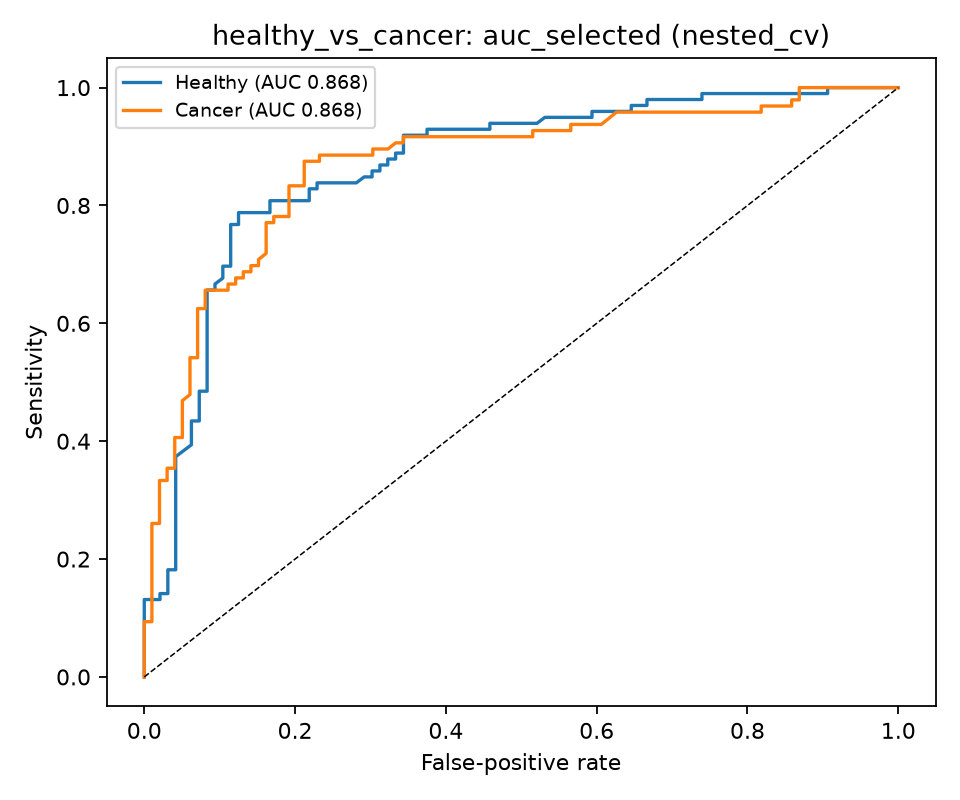

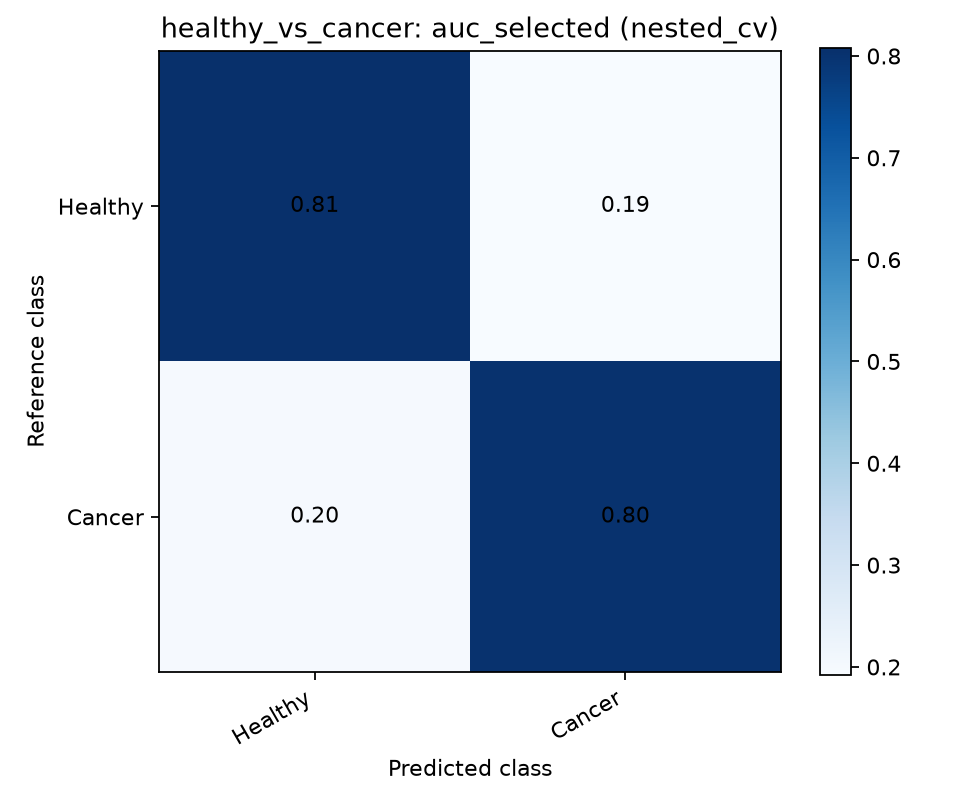

### healthy_vs_cancer: acc_selected

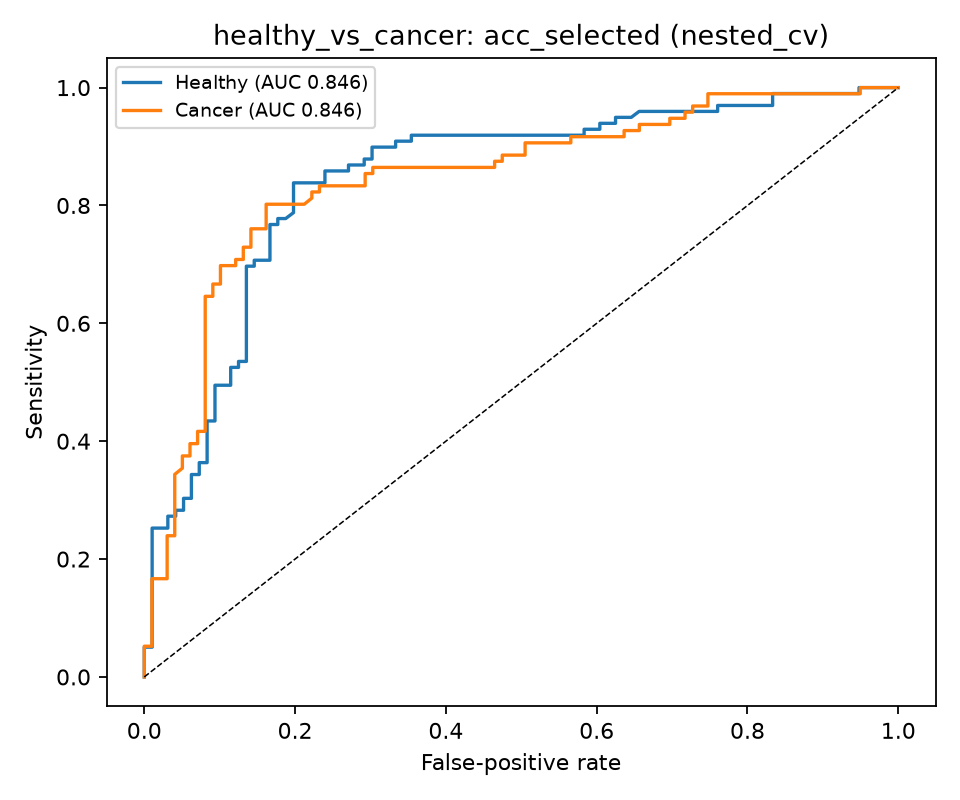

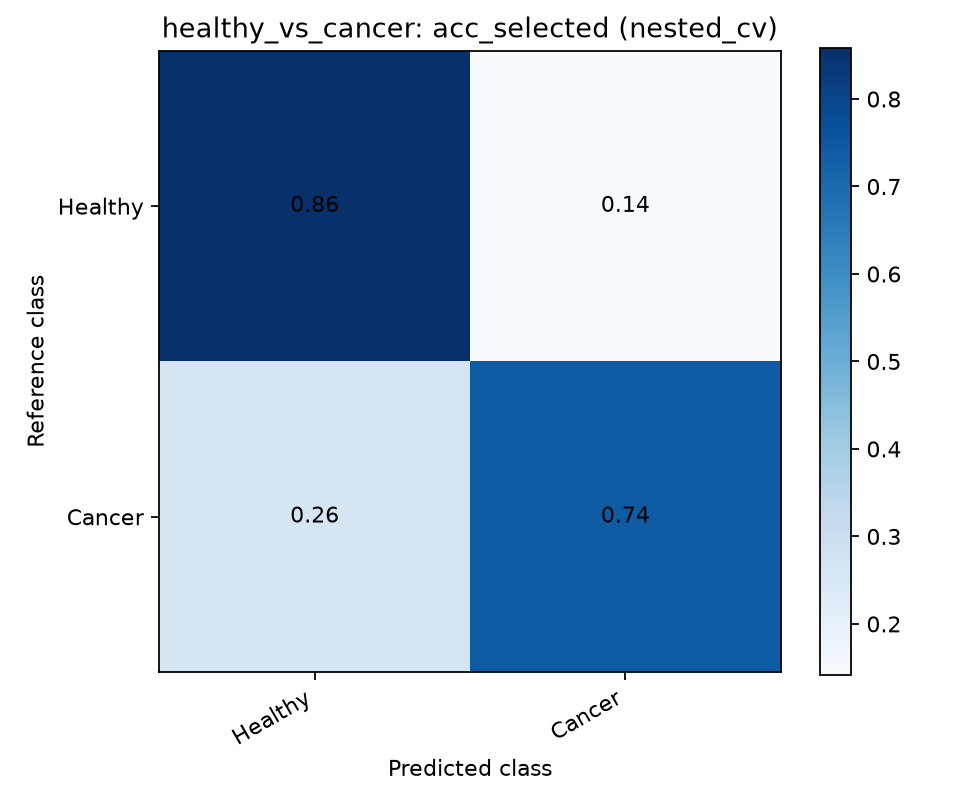

### healthy_vs_cancer: f1_selected

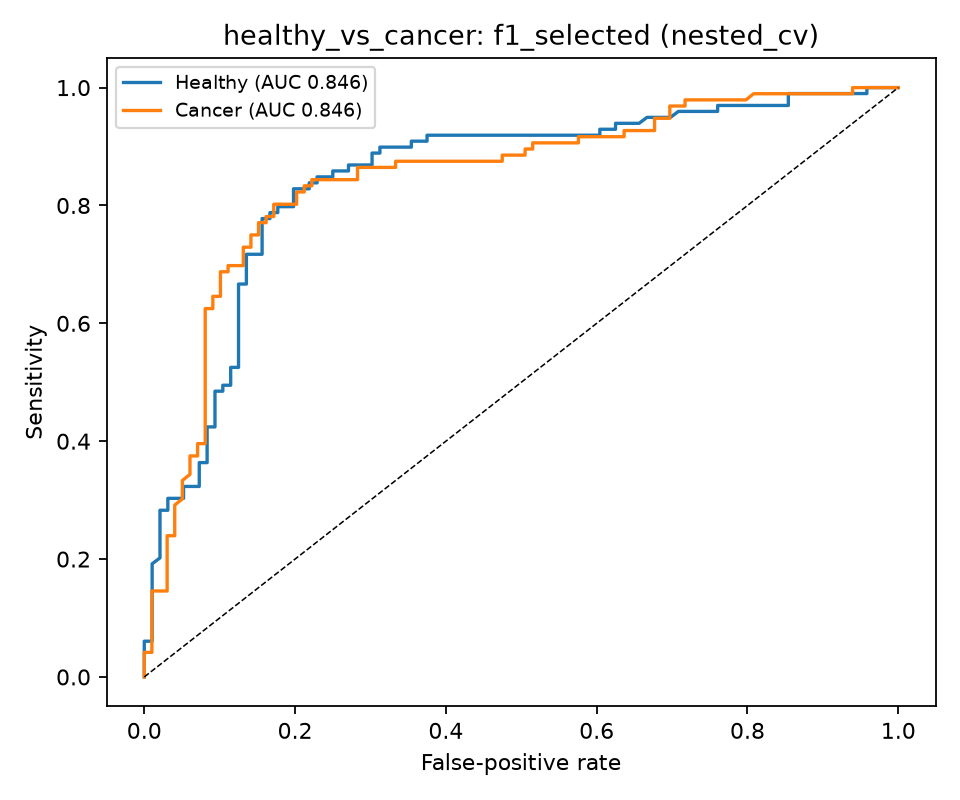

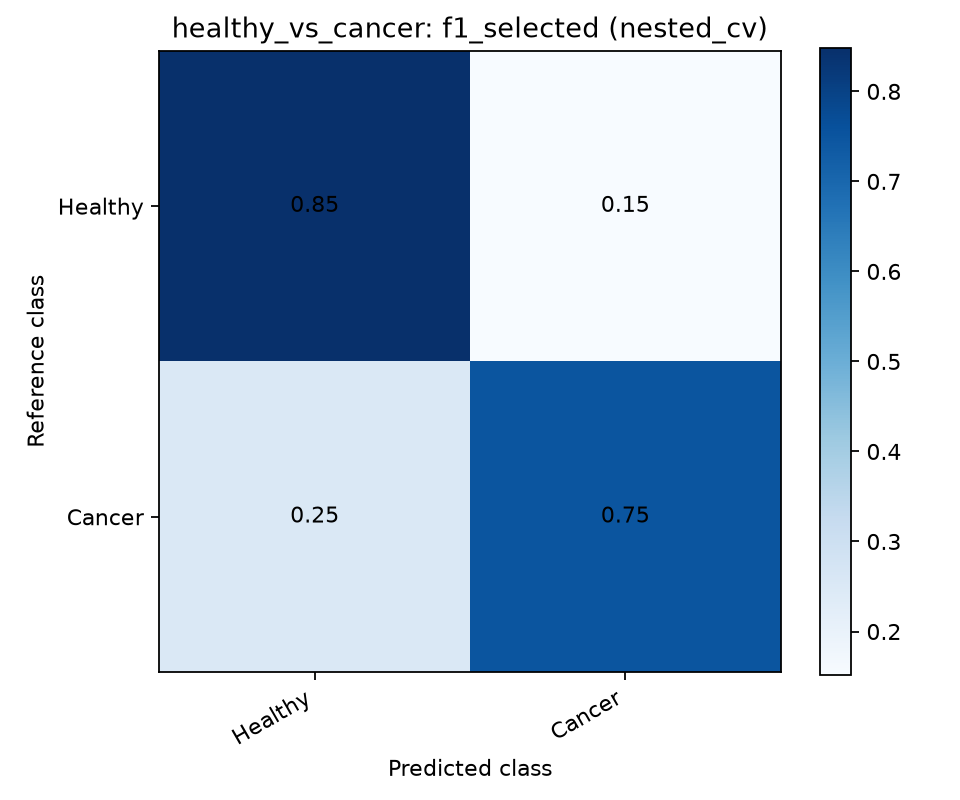

### healthy_vs_cancer: sensitivity_selected

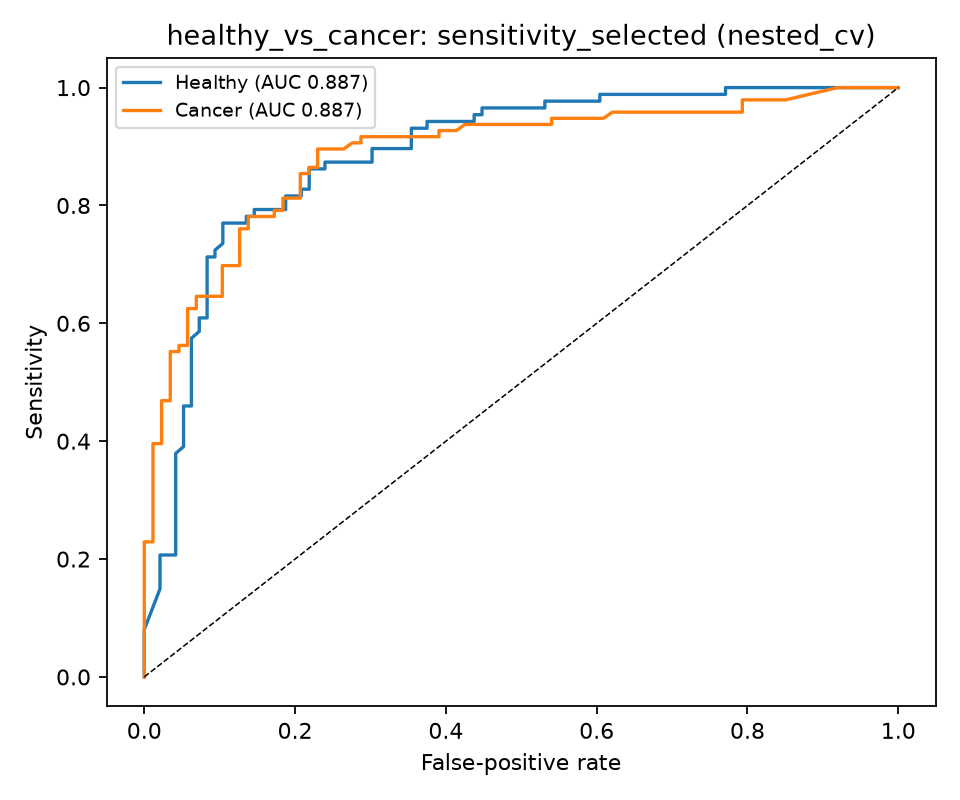

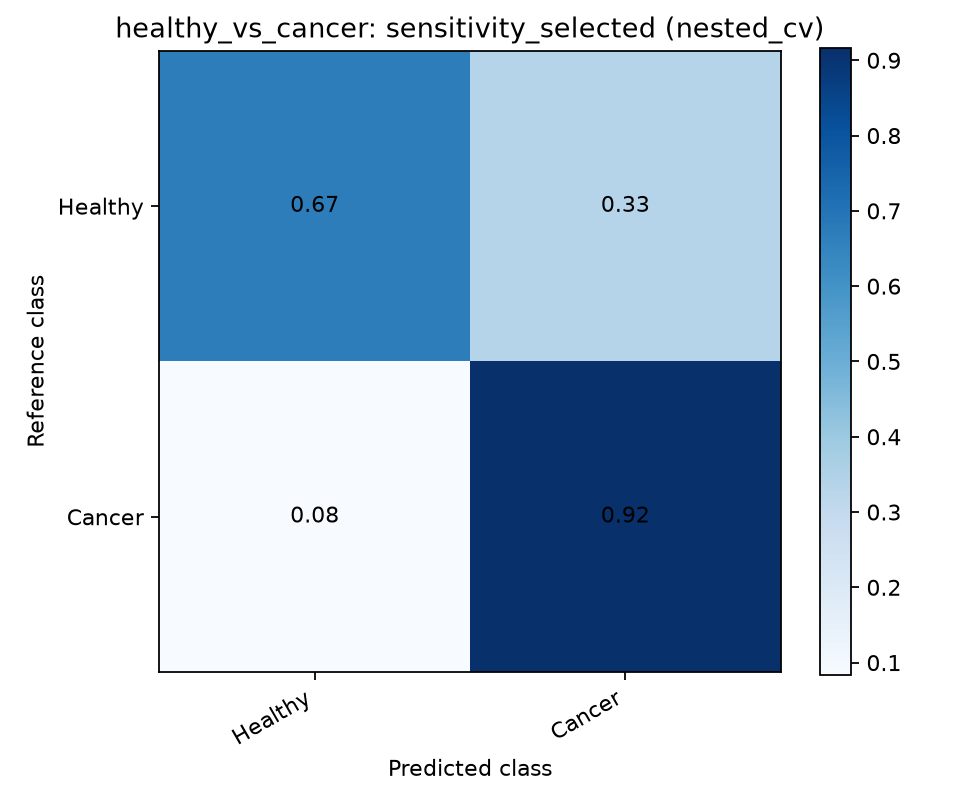

### cancer_vs_lr_hr: auc_selected

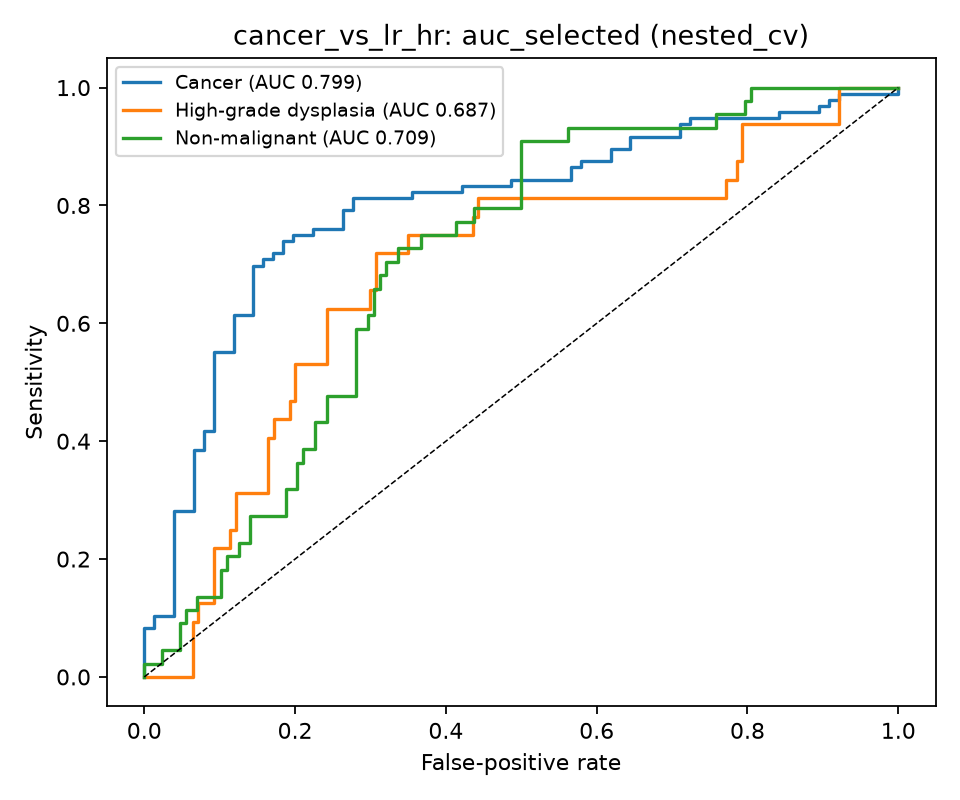

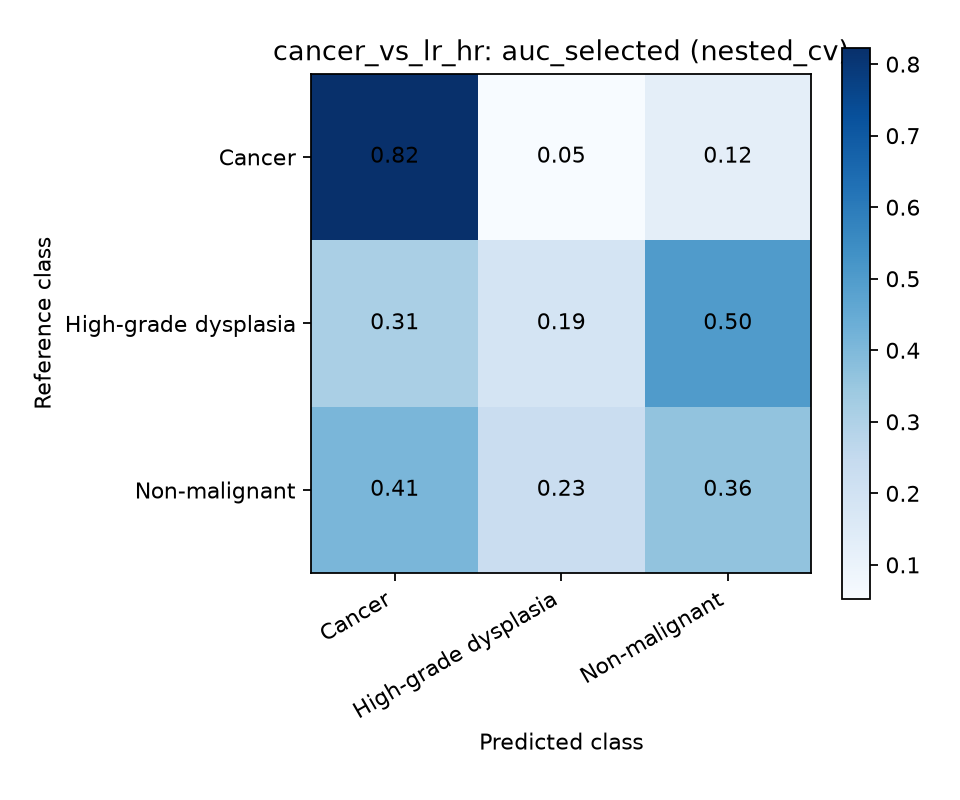

### cancer_vs_lr_hr: acc_selected

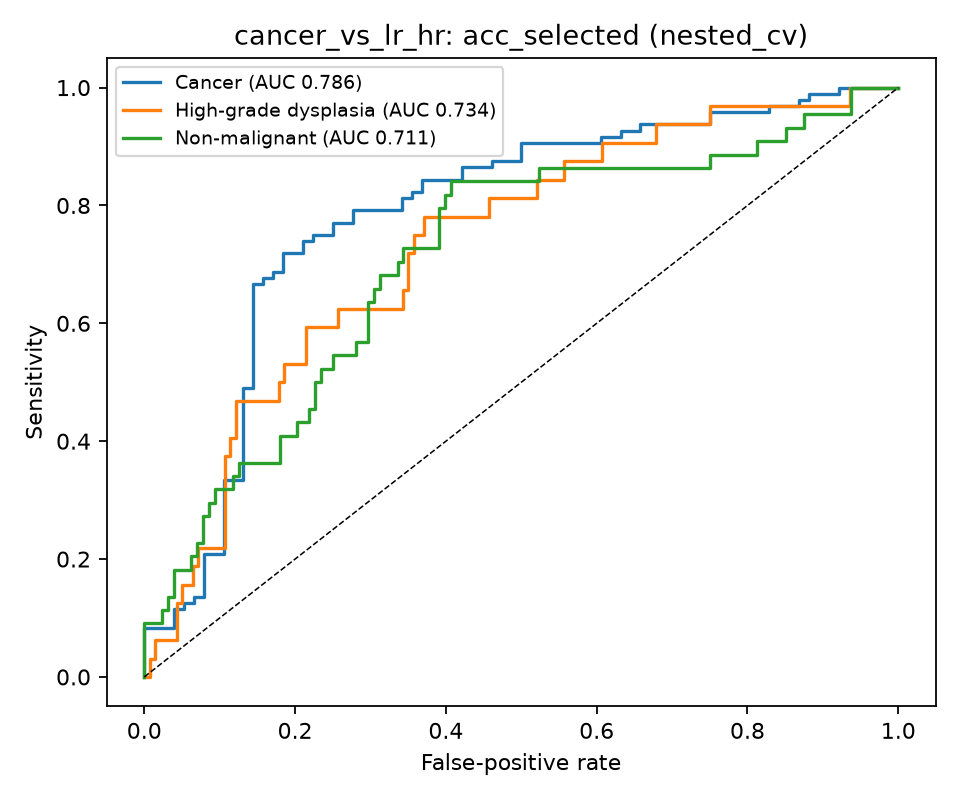

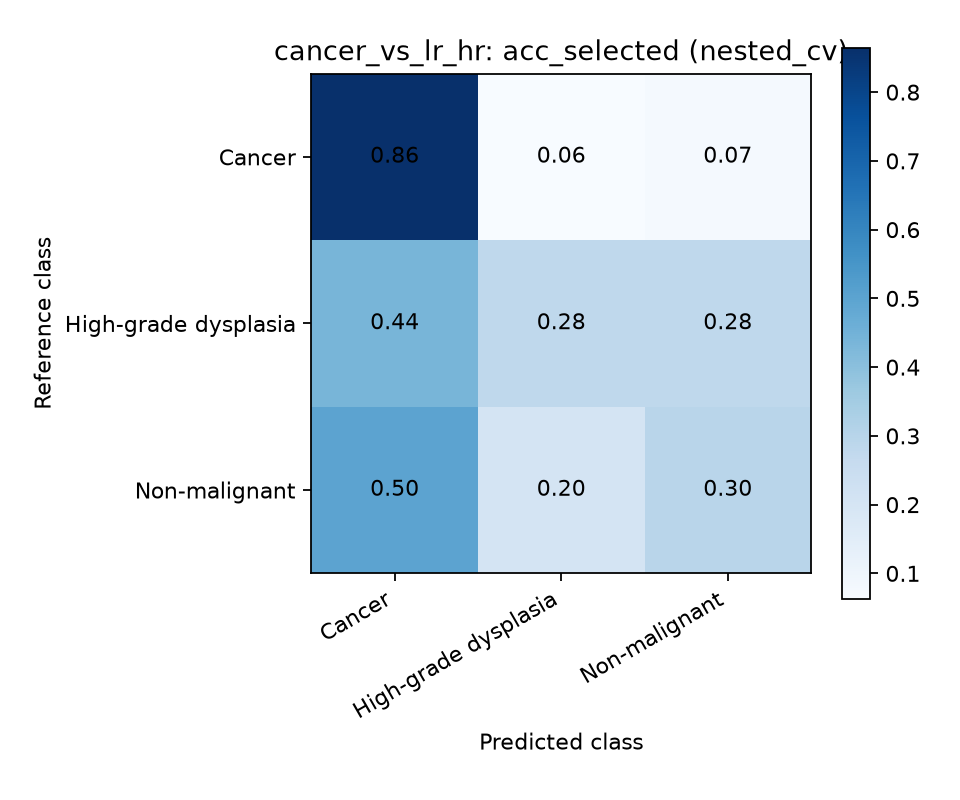

### cancer_vs_lr_hr: f1_selected

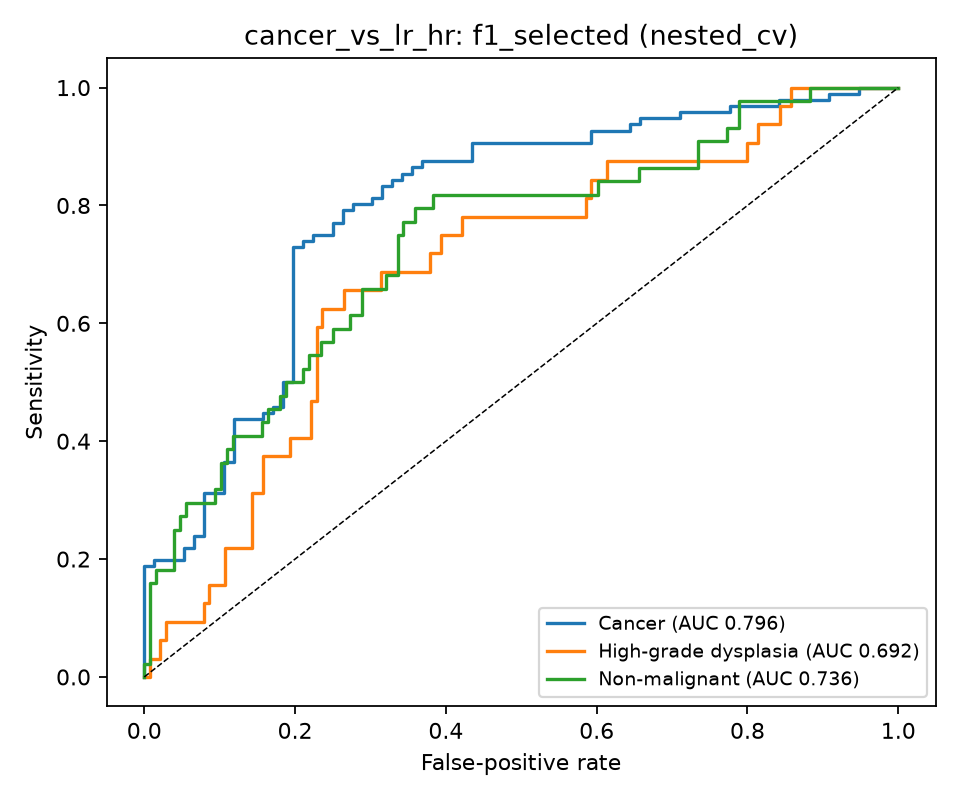

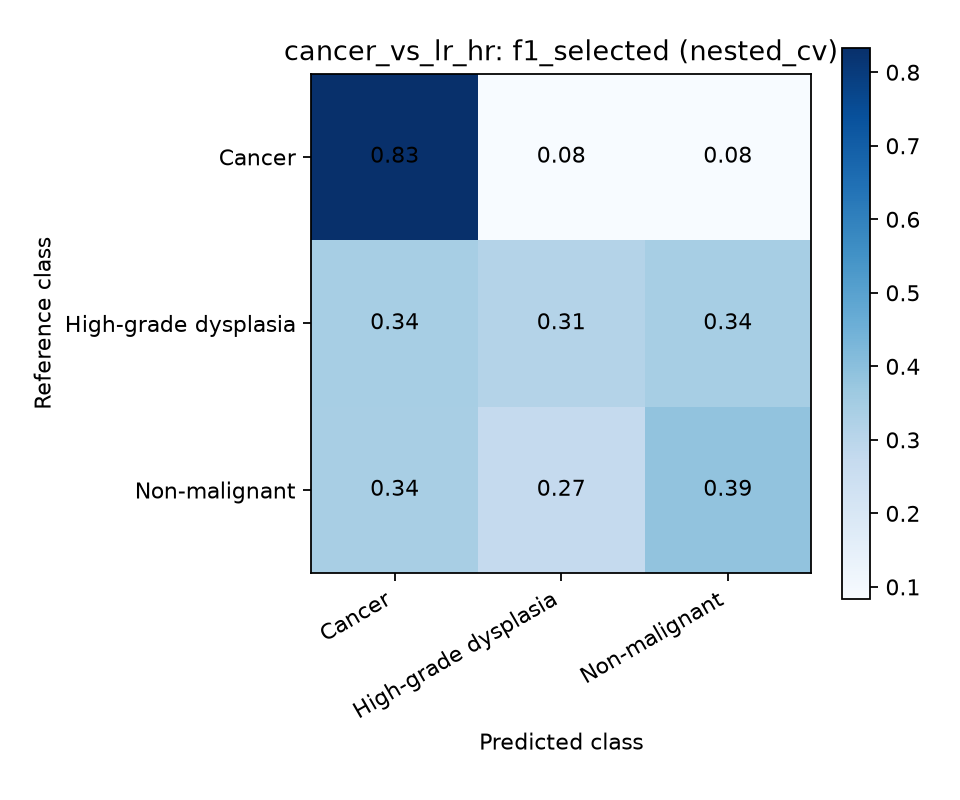

### cancer_vs_lr_hr: sensitivity_selected

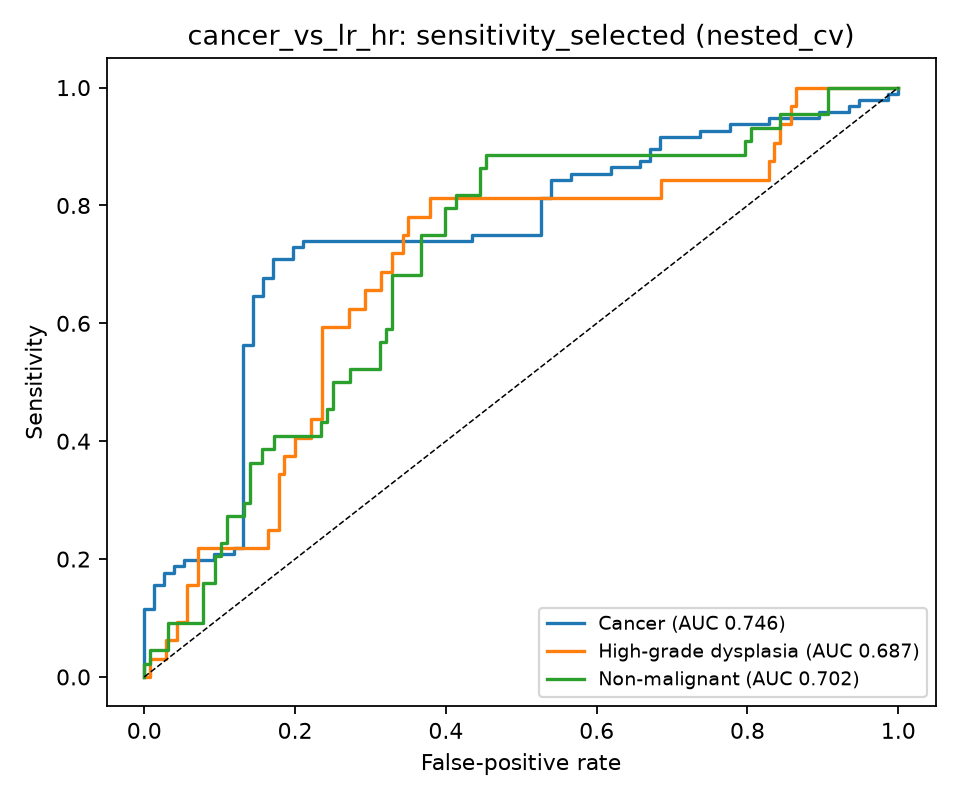

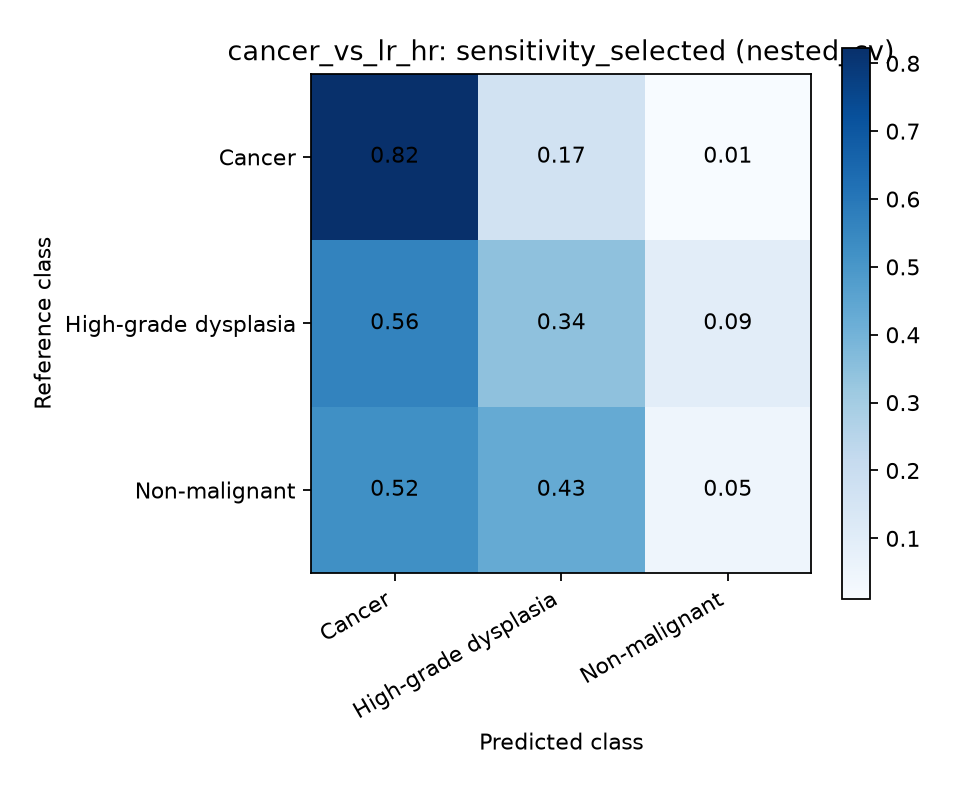

### MC: auc_selected

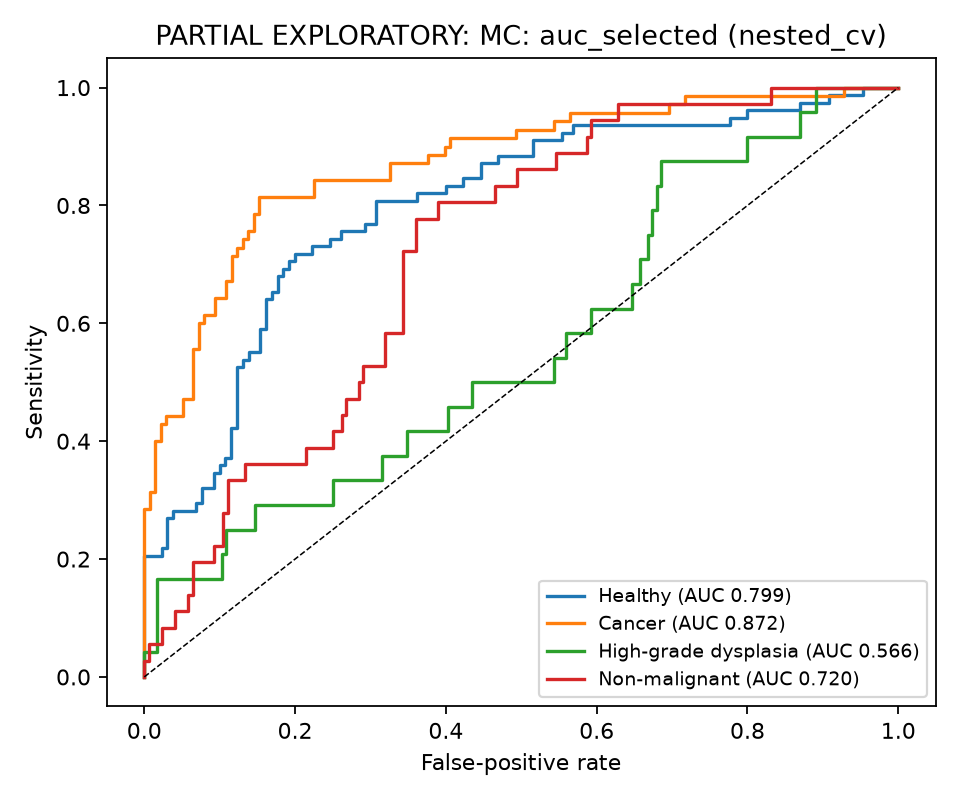

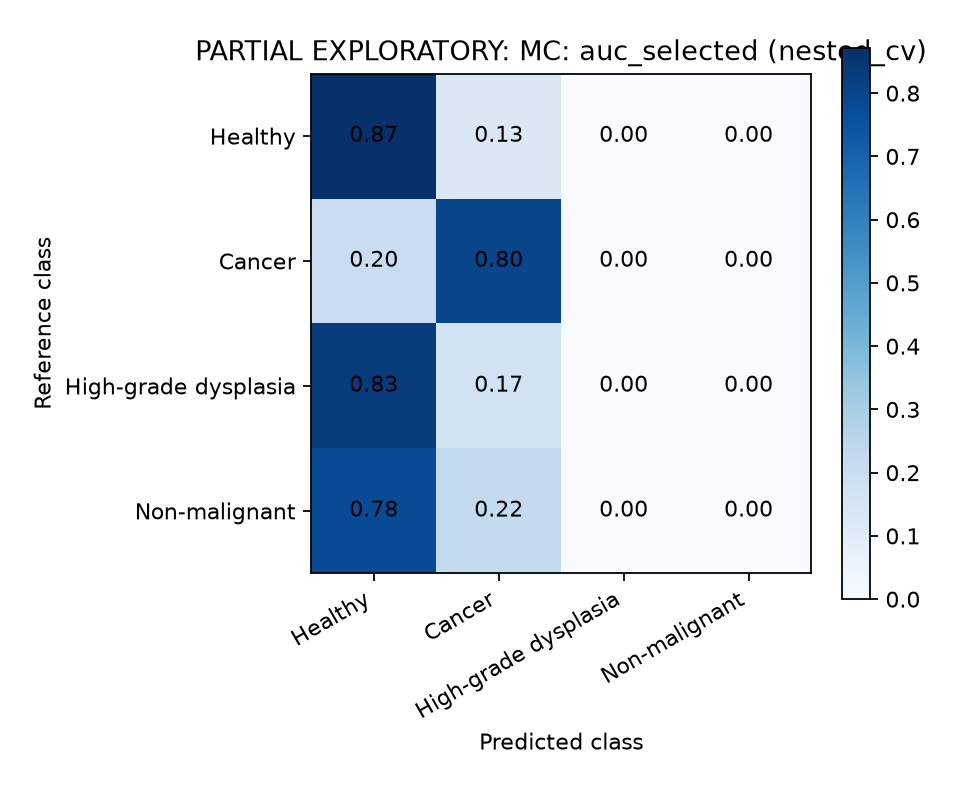

### MC: acc_selected

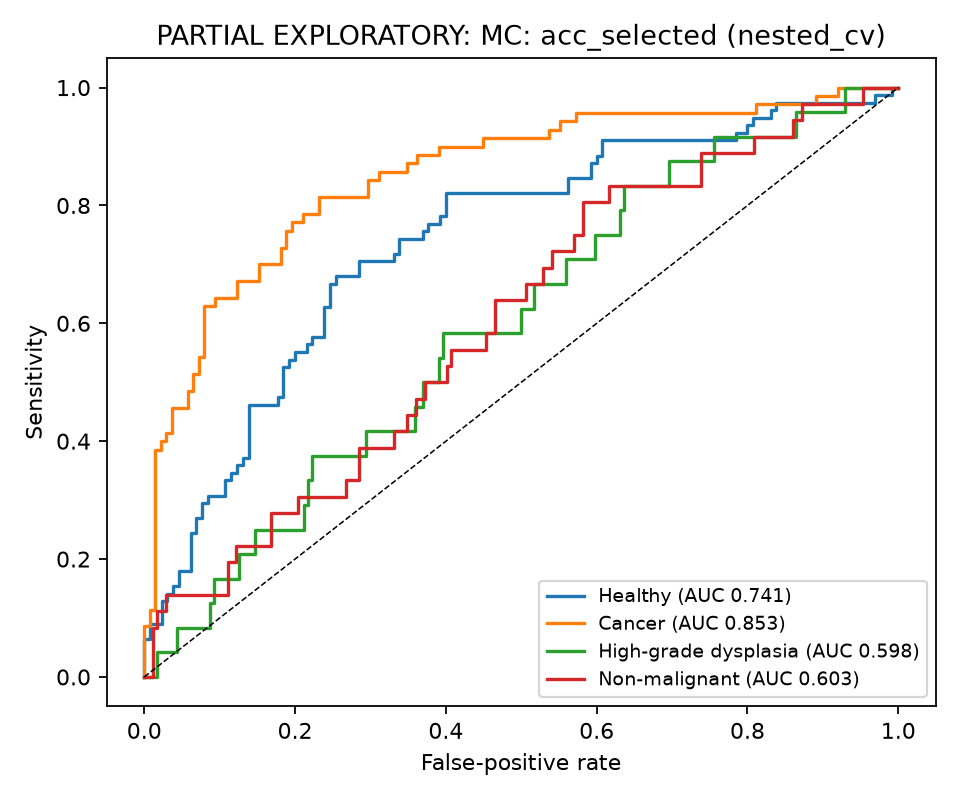

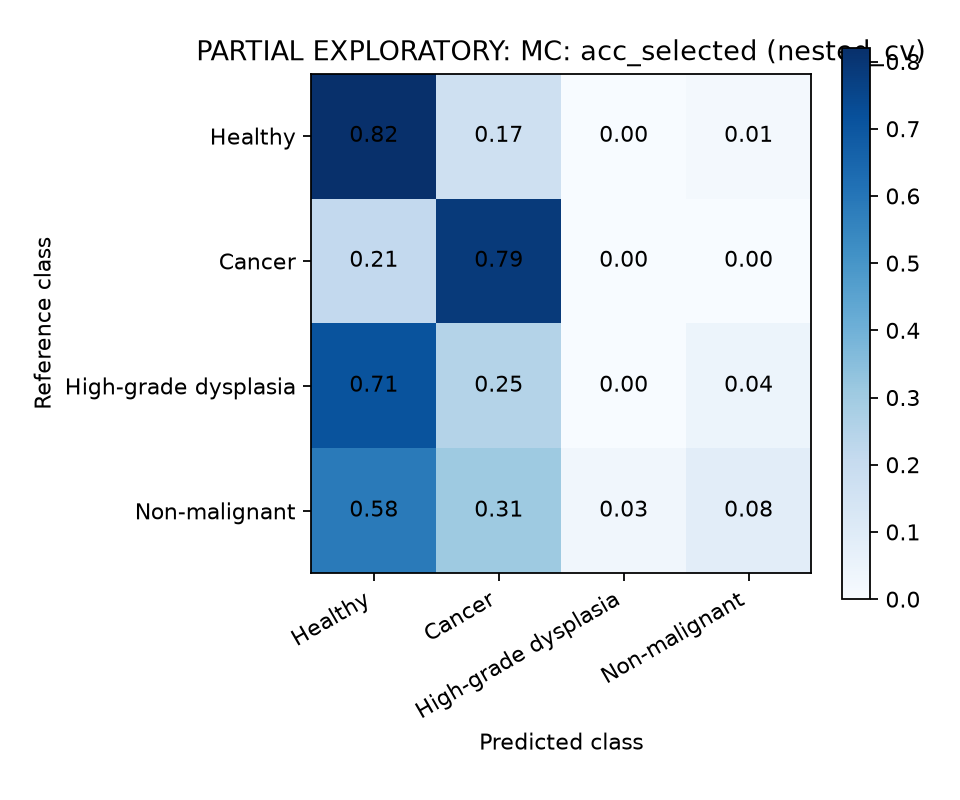

### MC: f1_selected

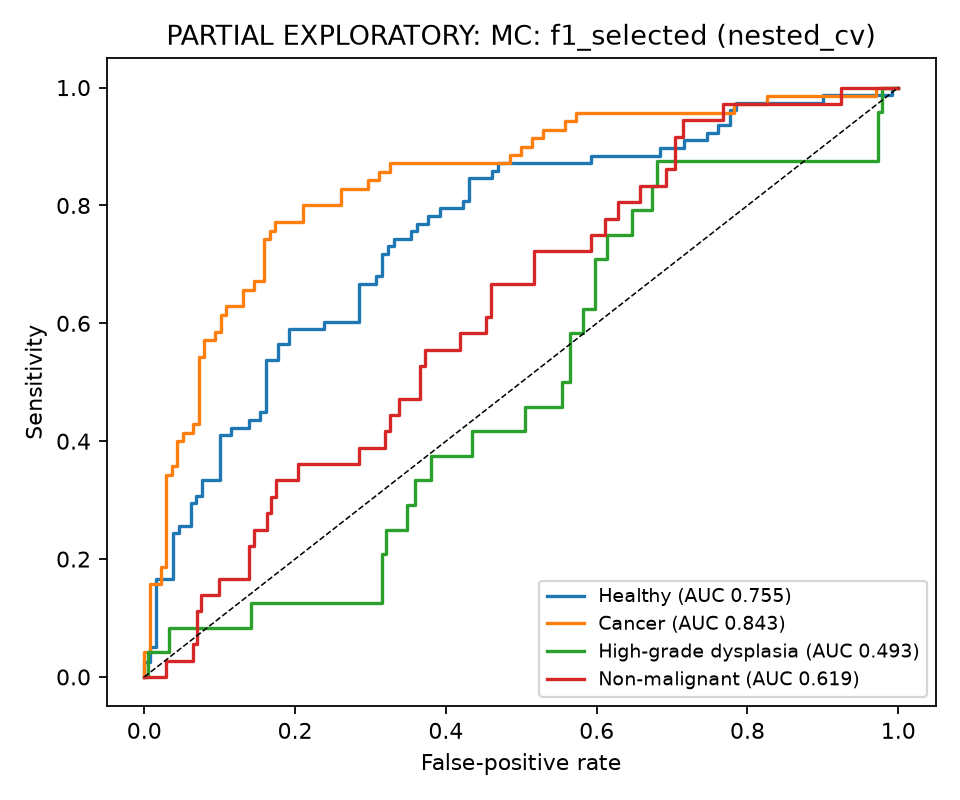

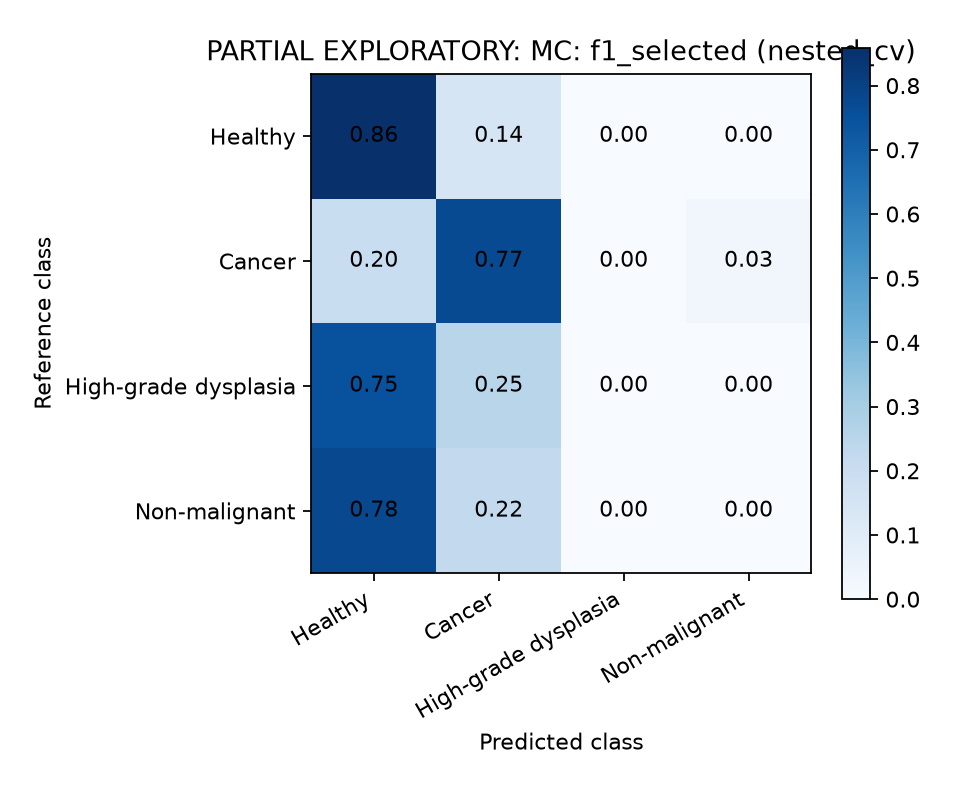

### MC: sensitivity_selected

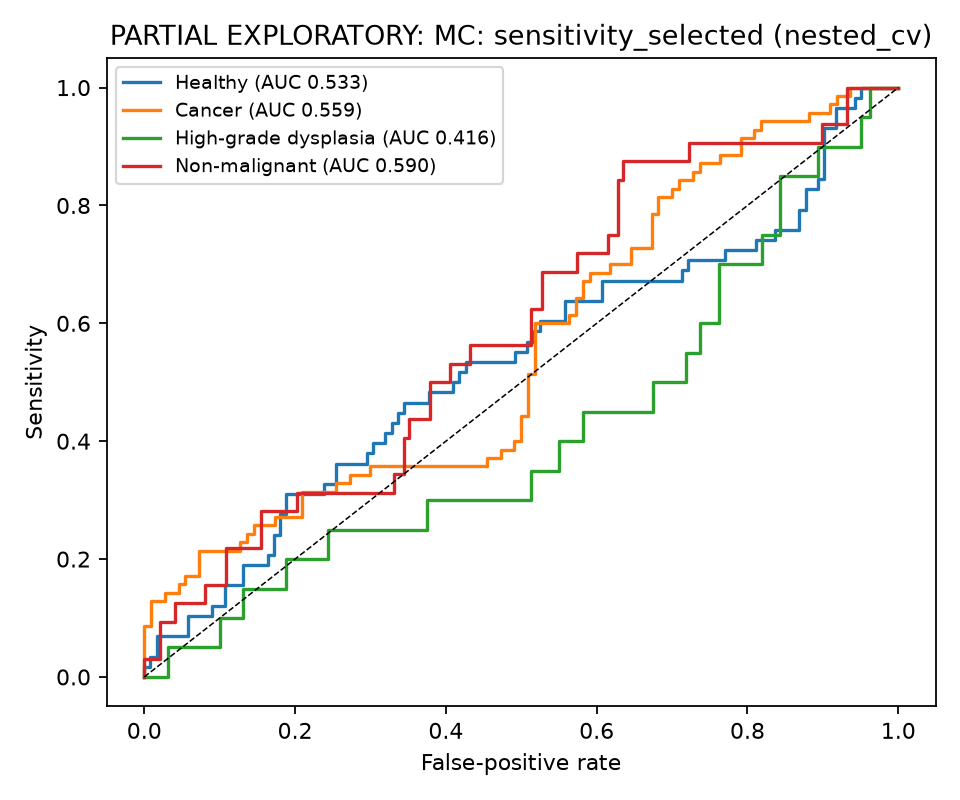

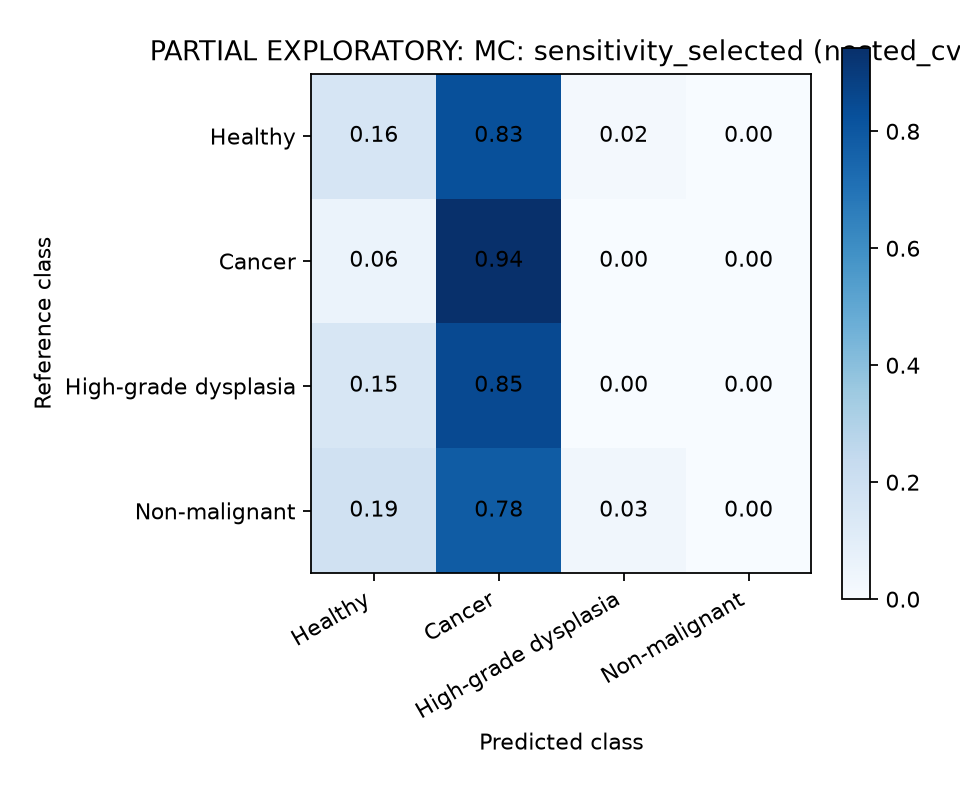

### highrisk_vs_lowrisk: auc_selected

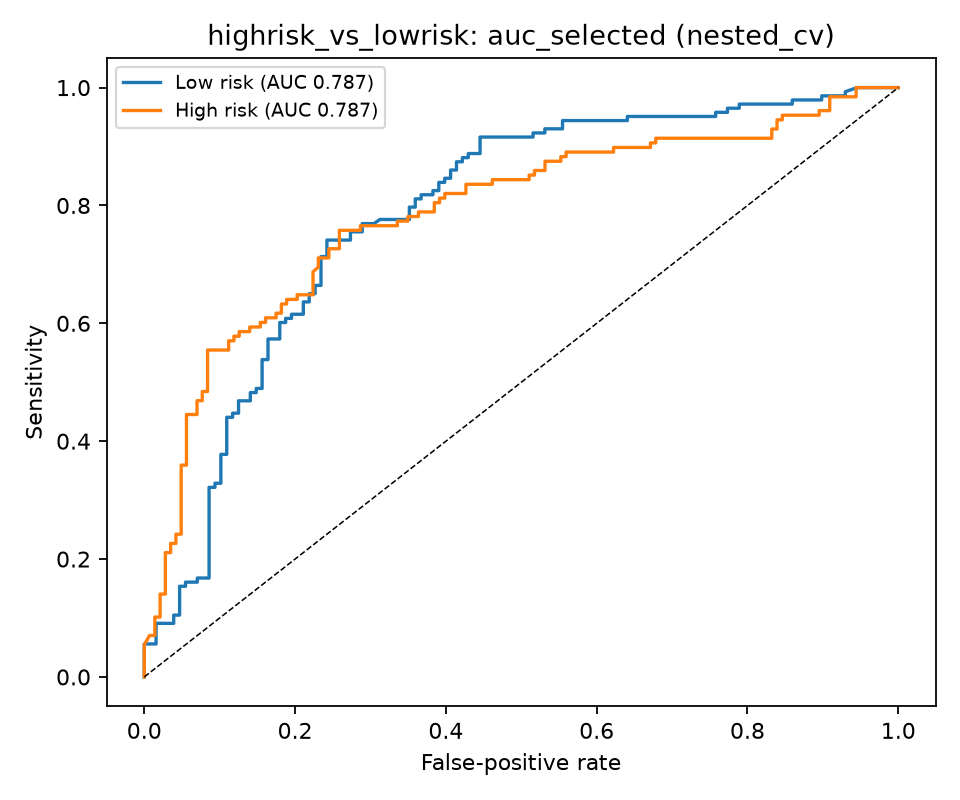

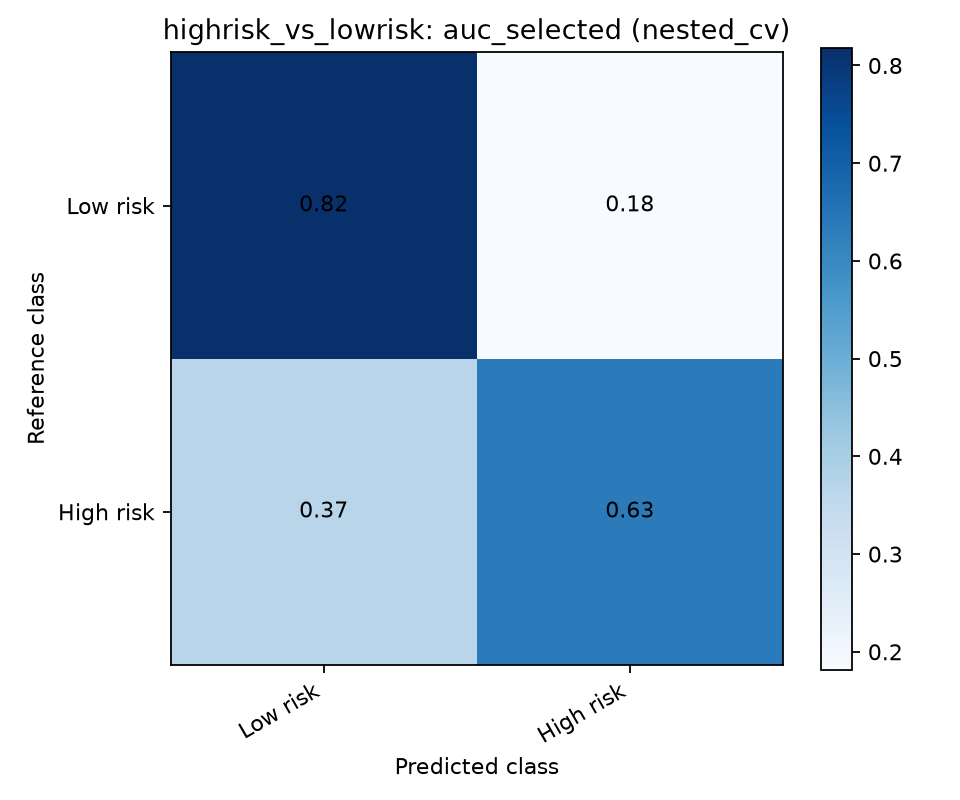

### highrisk_vs_lowrisk: acc_selected

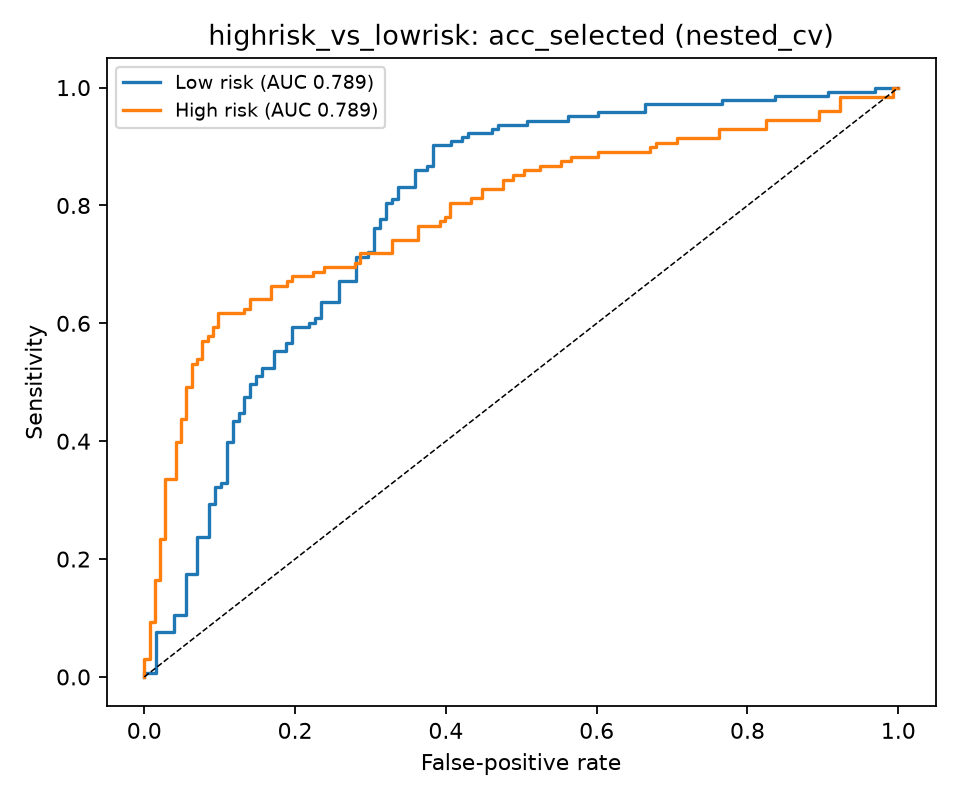

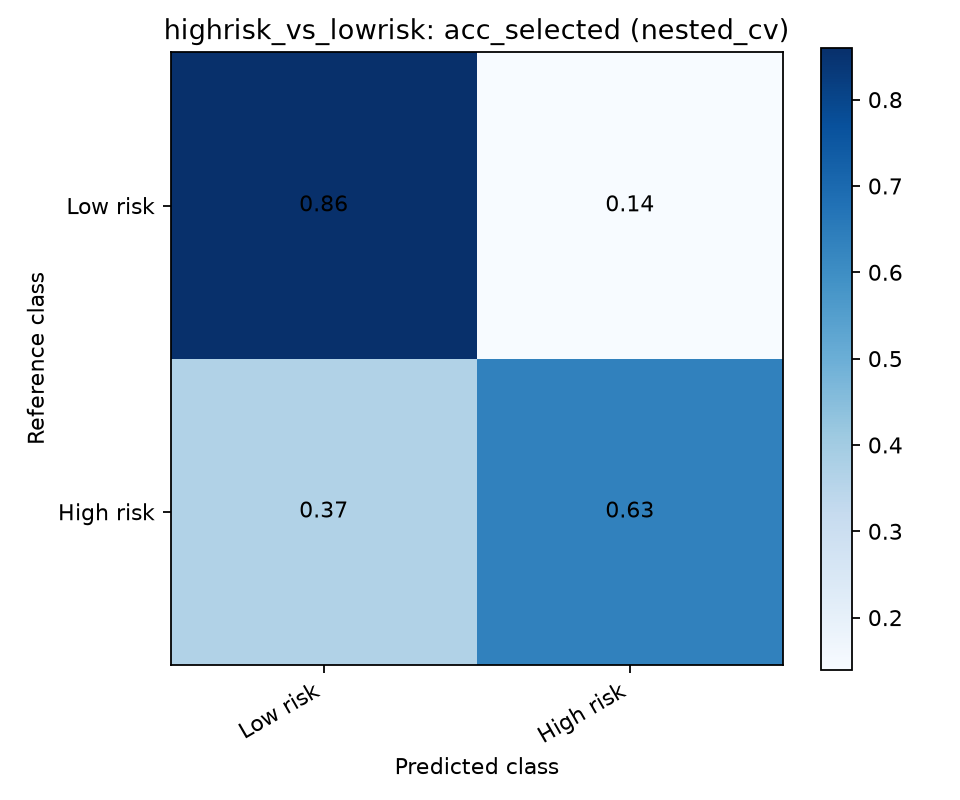

### highrisk_vs_lowrisk: f1_selected

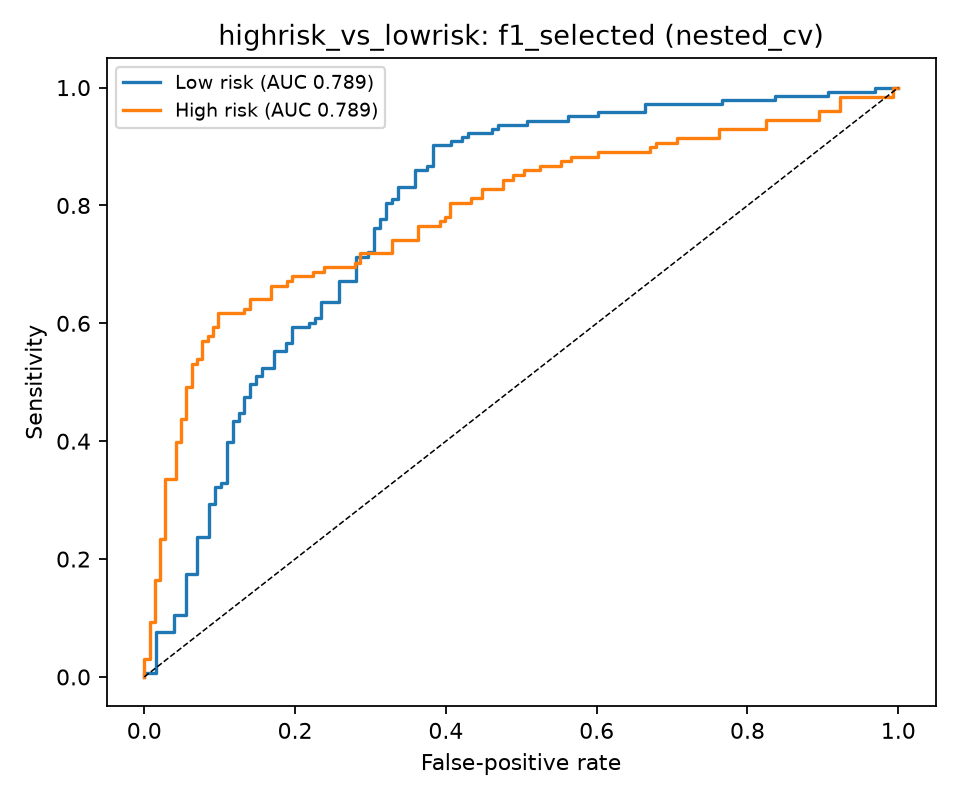

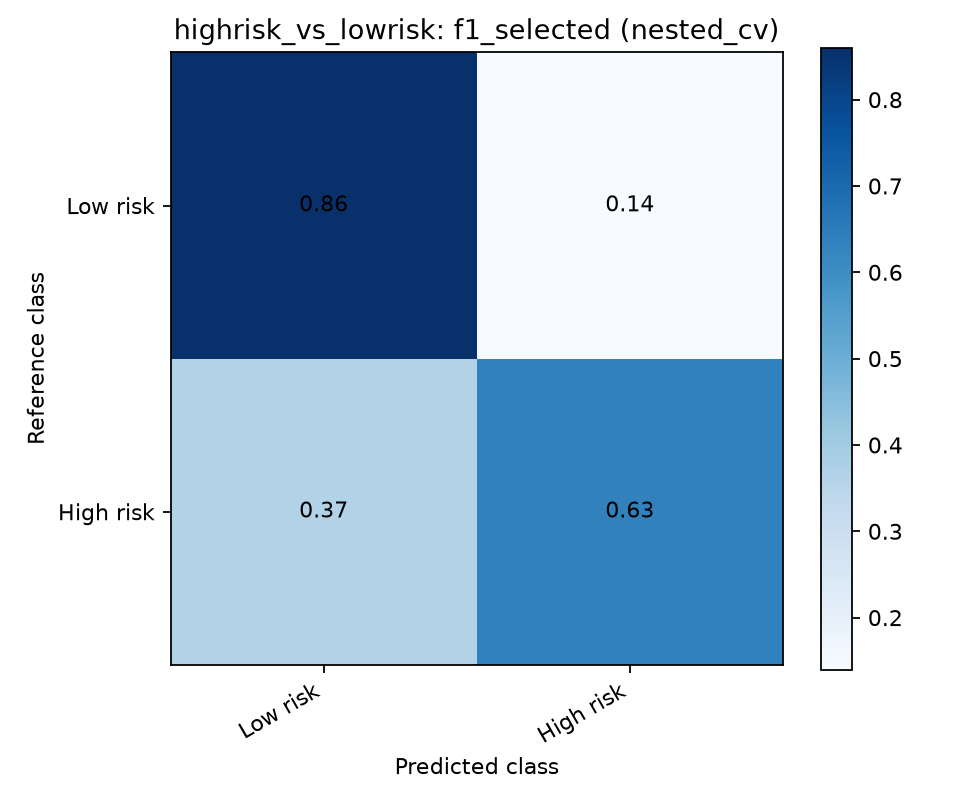

### highrisk_vs_lowrisk: sensitivity_selected

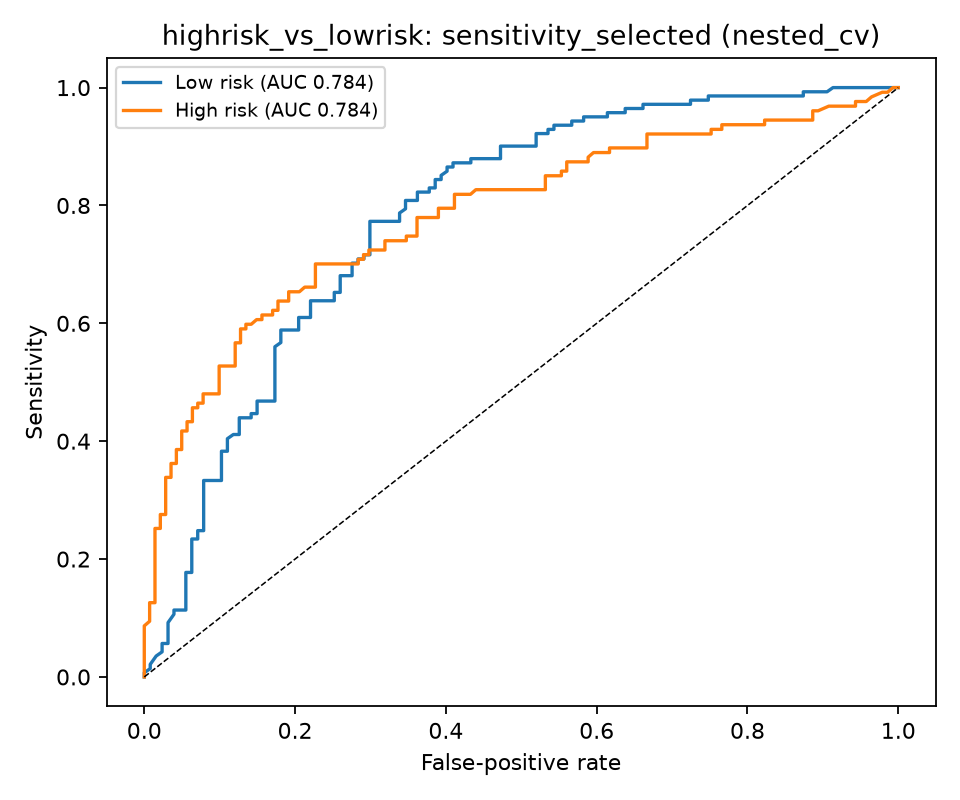

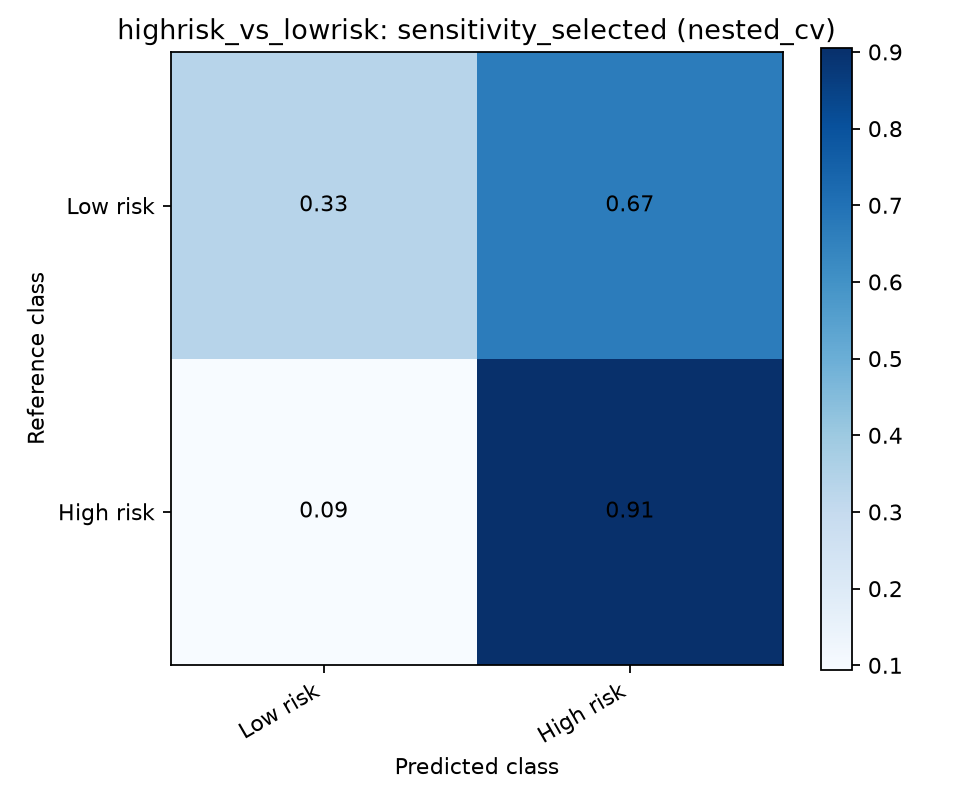

In [7]:
OBJECTIVES = ["auc", "acc", "f1", "sensitivity"]
PLOT_MODELS = ["selected"]  # alternativ z.B. ['selected', 'svm', 'rf', 'lr']
PLOT_FILES = [
    "ROC.png",
    "CM_norm.png",
]  # zusätzlich: CM.png, calibration.png, decision_curve.png
for task in TASKS:
    for goal in OBJECTIVES:
        for model in PLOT_MODELS:
            stream = f"{goal}_{model}"
            folder = RESULTS / f"plots_{task}_{goal}" / stream
            display(Markdown(f"### {task}: {stream}"))
            found = False
            for filename in PLOT_FILES:
                path = folder / filename
                if path.is_file():
                    found = True
                    display(Image(filename=str(path), width=650))
            if not found:
                print("Kein Gesamtplot verfügbar; unavailable_results.csv beachten.")

## Vollständiges Dateiverzeichnis und zusätzliche Audits

Alle gespeicherten CSV/JSON/PNG/PDF-Dateien bleiben im kopierten Verzeichnis verfügbar. Große Rohvorhersage- und Suchtabellen werden nicht ungefragt vollständig geladen. Die Pfade unten sind relativ zum Ergebnisordner. Dies ist eine Ansicht vorhandener Ergebnisse, keine automatische Manuskriptänderung.


In [8]:
for folder in ["quality", "repeatability"]:
    for path in sorted((RESULTS / folder).glob("*.csv")):
        show_table(path, limit=30)
files = [
    dict(path=str(p.relative_to(RESULTS)), bytes=p.stat().st_size)
    for p in sorted(RESULTS.rglob("*"))
    if p.is_file() and p.suffix in {".csv", ".json", ".pdf", ".png", ".md"}
]
inventory = pd.DataFrame(files)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(inventory)
print("Dateien direkt im Jupyter-Dateibrowser unter:", RESULTS)

**quality/class_by_location.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/quality/class_by_location.csv

,pathology,Unnamed: 1,alveolar ridge,anterior tongue,base tongue,buccal margin,buccal mucosa,floor of mouth,floor of the mouth,gingival mucosa,...,retromolar trigone / palate,right anterior tongue,right buccal mucosa,right retromolar trigone,right soft palate,soft palate,tonsil,tonsillar pillar,upper lip,ventral tongue
0,Cancer,0,3,0,9,0,3,1,15,2,...,0,0,0,0,0,1,16,0,1,1
1,Healthy,1,0,0,4,0,34,0,5,2,...,0,1,2,1,1,6,12,1,0,0
2,High-grade dysplasia,0,0,0,0,0,3,0,3,0,...,0,0,0,0,0,0,1,1,0,0
3,Non-malignant,0,0,1,2,1,4,0,3,0,...,0,0,0,0,0,2,1,0,0,2
4,NaN,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0


**quality/covariate_cluster_associations.csv**

/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955/quality/covariate_cluster_associations.csv

,variable,level,status,wald_chi2,df,p_value,n_patients,method,reason,n_coefficients,covariance_rank,p_holm
0,prior_radiation,No,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
1,prior_radiation,Yes,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
2,location,oral tongue,computed,15.391316,3.0,1.511015e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.137452e-02
3,location,base tongue,computed,9.982849,3.0,1.871249e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.987996e-01
4,location,floor of the mouth,computed,5.576719,3.0,1.341213e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
5,location,anterior tongue,unavailable,NaN,NaN,NaN,100,NaN,singular or ill-conditioned patient-cluster co...,3.0,1.0,NaN
6,location,tonsil,computed,11.527527,3.0,9.190010e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,3.032703e-01
7,location,buccal mucosa,computed,38.233536,3.0,2.522313e-08,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.828097e-07
8,location,soft palate,computed,9.183887,3.0,2.694333e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.352432e-01
9,location,palate,computed,4.859811,3.0,1.823550e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00


... (43 outputs left out)

,sample_id,patient_id,pathology,mean_coordinate_cv,mean_magnitude,scalar_repeat_cv,n_finite_test_means,repositioning_sd
0,0:0,0,Healthy,0.391493,285.895051,0.114473,3,32.727278
1,0:1,0,Cancer,0.448475,560.416640,0.268196,3,150.301668
2,1:0,1,Healthy,0.217883,683.701282,0.115949,3,79.274190
3,1:1,1,Cancer,0.199558,136.386613,0.021110,3,2.879113
4,1:2,1,NaN,0.465265,504.000779,0.267388,3,134.763852
5,2:0,2,Healthy,0.417408,271.030391,0.246002,3,66.674124
6,2:1,2,Cancer,0.529017,323.274215,0.361243,3,116.780473
7,3:0,3,Healthy,0.441225,253.519550,0.237187,3,60.131538
8,3:1,3,Cancer,0.170567,223.859973,0.053033,3,11.871961
9,4:0,4,Healthy,0.157564,844.747393,0.045478,3,38.417248


276 Zeilen; Vorschau mit 30 Zeilen. Vollständige Datei über den Link.


,path,bytes
0,BaselineResults.csv,17017
1,FinalResults.csv,103854
2,MC/FreqSel_ranking_MC_inner_folds.csv,484
3,MC/MaskSel_ranking_MC_inner_folds.csv,484
4,MC/candidate_failures.json,3
5,MC/classes.json,312
6,MC/classification_outputs.csv,527271
7,MC/corrected_resampled_tests.csv,28463
8,MC/cv_comparison_fold_differences.csv,56790
9,MC/cv_demographics_availability.csv,1298190


Dateien direkt im Jupyter-Dateibrowser unter: /home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-finetuning-20261102-122955
